# **Detection of Mental Health Disorders from Social Media Text Data**

## **MSc Dissertation - Artificial Intelligence and Data Science, University of York Europe Campus**

**Author: Evangelia Tsakanika**

**Supervisor: Dr. Ioanna Stamatopoulou**

---

### **Purpose**

This notebook implements the complete experimental pipeline of the dissertation: data auditing, exploratory analysis, classical and transformer-based classifiers, statistical evaluation and a systematic study of how well models generalise beyond the data on which they were trained. Every number reported throughout the dissertation report and the Results chapter is produced in this notebook and every figure is exported at print resolution.

### **Research Objectives**

| | Question
|---|---|
| **RQ1** | How accurately can classical and transformer models detect mental-health signals across four Reddit-derived tasks and a human-annotated stress corpus?
| **RQ2** | How much of that accuracy is recoverable from stylistic *shortcut* features that carry no psychological content?
| **RQ3** | How well do models generalise to unseen communities, and to data labelled by an entirely different procedure?
| **RQ4** | Where do models fail, and which conditions are confused with one another?


### **Data**

| Corpus | Tasks Used | Label Provenance |
|---|---|---|
| Hasan & Saquer benchmark suite [1] | *general* (binary, plus an external set of unseen subreddits), *multiclass* (7 classes), *suicidality*, *bipolar* | subreddit membership with self-identification filtering; human-verified sample |
| Dreaddit [2] | *dreaddit* (binary stress) | crowdsourced human annotation of the text itself |

The two corpora were selected because they **differ in how their labels were produced**. This makes the cross-dataset experiment informative: a model that has learned to recognise psychological distress should transfer reasonably well to the other corpus, whereas a model that has learned the topical fingerprint of particular communities should not. Because the corpora also differ in the construct they measure and in the length of their texts, transfer scores alone cannot fully separate these explanations; the analysis of errors by community was therefore used to examine which of them the evidence supports.

### **Pipeline**

```text
            Raw CSV files
                  │
                  ▼
      Loading and label mapping
                  │
                  ▼
        Cleaning and data audit
   (leakage, label conflicts, overlap)
                  │
                  ▼
      Exploratory data analysis
                  │
         ┌────────┴──────────┐
         ▼                   ▼
 Classical models  Transformer (RoBERTa)
         │                   │
         └────────┬──────────┘
                  ▼
          Cached predictions
                  │
                  ▼
   Evaluation: macro-F1, AUROC and
    bootstrap confidence intervals
                  │
     ┌────────────┼────────────┐
     ▼            ▼            ▼
 In-domain  Generalisation  Errors
 RQ1, RQ2        RQ3          RQ4
```

### **How to run**

1. **Google Colab** → *Runtime → Change runtime type → T4 GPU*.
2. Place the data in Google Drive:
```
MyDrive/Dissertation - Evangelia Tsakanika/data/
├── hasan_saquer/   ← the nine CSV files from Zenodo
└── dreaddit/       ← dreaddit-train.csv, dreaddit-test.csv
```
   (A different location can be used by setting the environment variable `DISS_ROOT`.)
3. Run all cells in order.
4. Every experiment is cached to Drive the moment it finishes. If Colab disconnects, simply run the notebook again: completed experiments are loaded from the cache rather than recomputed.

Outputs: `results/` (tables, cached predictions, environment record) and `figures/` (300-dpi PNG).

## 0. Environment and configuration

In [1]:
import os, sys, json, re, time, gc, hashlib, random, platform, importlib.util, warnings, contextlib
from pathlib import Path

try:                                   # robust across Colab/Python versions
    import google.colab                # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
print(f"Python {platform.python_version()} | running on Colab: {IN_COLAB}")

Mounted at /content/drive
Python 3.13.16 | running on Colab: True


### 0.1 Configuration

Every experimental decision is set in this single cell, so the full design of the study is visible in one place and can be reported in the Methodology chapter. The defaults reproduce the dissertation's experiments; the override dictionaries should stay empty unless §1.3 shows that a column or label was detected incorrectly.

In [3]:
# ------------------------------------------------------------------ paths
PROJECT_ROOT = Path(os.environ.get(
    "DISS_ROOT", "/content/drive/MyDrive/Dissertation - Evangelia Tsakanika" if IN_COLAB else "."))
HS_DIR       = PROJECT_ROOT / "data" / "hasan_saquer"
DREADDIT_DIR = PROJECT_ROOT / "data" / "dreaddit"
RESULTS_DIR  = PROJECT_ROOT / "results"
FIG_DIR      = PROJECT_ROOT / "figures"
CACHE_DIR    = RESULTS_DIR / "cache"
TABLE_DIR    = RESULTS_DIR / "tables"
for d in (FIG_DIR, CACHE_DIR / "preds", TABLE_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------ experiment
SEED             = 42
TASKS_TO_RUN     = ["dreaddit", "general", "suicidality", "bipolar", "multiclass"]
RUN_CLASSICAL    = True
RUN_TRANSFORMERS = True    # disabled automatically if torch/transformers are missing
FORCE_RERUN      = False   # True = ignore the cache and recompute everything

# ------------------------------------------------------------------ data overrides
TEXT_COLUMNS   = {}    # e.g. {"general": ["title", "text"]}
LABEL_COLUMNS  = {}    # e.g. {"general": "label"}
POSITIVE_LABEL = {}    # e.g. {"general": "mental"}   (binary tasks only)
COMBINE_TITLE  = True  # prepend a 'title' column to the post body when one exists
MIN_CHARS      = 10

# ------------------------------------------------------------------ transformers
TRANSFORMER_MODELS    = ["roberta-base"]   # add "mental/mental-roberta-base" once access is granted
TRANSFORMER_SEEDS     = [42]               # add seeds (e.g. [42, 13, 7]) to measure training variance
TRANSFORMER_MAX_TRAIN = None               # None = full training set; e.g. 40_000 if GPU time is short
MAX_LENGTH       = 256
EPOCHS           = {"dreaddit": 4, "default": 2}
BATCH_SIZE       = 32
EVAL_BATCH       = 128
LR               = 2e-5
WEIGHT_DECAY     = 0.01
WARMUP_FRAC      = 0.06
VAL_FRAC         = 0.10
SMOKE_TEST_FIRST = False   # a 1-2 minute end-to-end check before the real runs

# ------------------------------------------------------------------ statistics
N_BOOTSTRAP = 1000
CI_LEVEL    = 0.95

print("Project root:", PROJECT_ROOT.resolve())

Project root: /content/drive/MyDrive/Dissertation - Evangelia Tsakanika


In [4]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.metrics import roc_auc_score, roc_curve
from IPython.display import display, Markdown

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed()
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
                     "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    print(f"figure saved: figures/{name}.png")

def save_table(df, name, index=True):
    df.to_csv(TABLE_DIR / f"{name}.csv", index=index)
    print(f"table saved: results/tables/{name}.csv")

TORCH_OK = all(importlib.util.find_spec(m) is not None for m in ("torch", "transformers"))
if RUN_TRANSFORMERS and not TORCH_OK:
    print("[!] torch/transformers not installed -- transformer experiments disabled.")
    RUN_TRANSFORMERS = False

ENV = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
       "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
       "colab": IN_COLAB, "seed": SEED}
if TORCH_OK:
    import torch, transformers
    ENV.update({"torch": torch.__version__, "transformers": transformers.__version__,
                "cuda": torch.cuda.is_available(),
                "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None})
    if RUN_TRANSFORMERS and not torch.cuda.is_available():
        print("[!] No GPU detected: transformer training on CPU is impractically slow.\n"
              "    On Colab: Runtime -> Change runtime type -> T4 GPU.")
(RESULTS_DIR / "environment.json").write_text(json.dumps(ENV, indent=2))
pd.Series(ENV, name="value").to_frame()

,value
python,3.13.16
numpy,2.1.3
pandas,2.2.3
scikit-learn,1.6.1
matplotlib,3.10.0
colab,True
seed,42
torch,2.11.0+cu130
transformers,5.21.0
cuda,True


## 1. Data

### 1.1 Task definitions

Each task consists of a training split and one or more evaluation splits **exactly as released by the dataset authors**. The data are never re-split: using the published splits keeps our results directly comparable with those reported in the original papers. The only exception is the validation set of the transformer, which is drawn from the training split (§6); the test sets are never touched.

The **transfer group** defines the cross-dataset study of §8: models trained on either member are evaluated on the evaluation sets of both. The two tasks share a label semantics - 1 means the text signals psychological distress, 0 means it does not - which makes the comparison interpretable even though the underlying constructs (mental disorder versus acute stress) are not identical. That construct difference is itself a limitation to be discussed.

In [5]:
TASKS = {
    "general":     {"corpus": "hs", "kind": "binary",
                    "train": "general_mental_labeled_train.csv",
                    "eval": {"test": "general_mental_labeled_test.csv",
                             "external": "general_mental_labeled_test_secondary.csv"}},
    "multiclass":  {"corpus": "hs", "kind": "multiclass",
                    "train": "multi_class_mental_labeled_train.csv",
                    "eval": {"test": "multi_class_mental_labeled_test.csv"}},
    "suicidality": {"corpus": "hs", "kind": "binary",
                    "train": "suicidality_labeled_train.csv",
                    "eval": {"test": "suicidality_labeled_test.csv"}},
    "bipolar":     {"corpus": "hs", "kind": "binary",
                    "train": "bipolar_train.csv",
                    "eval": {"test": "bipolar_test.csv"}},
    "dreaddit":    {"corpus": "dreaddit", "kind": "binary",
                    "train": "dreaddit-train.csv",
                    "eval": {"test": "dreaddit-test.csv"}},
}
TRANSFER_GROUP = ["general", "dreaddit"]
TRANSFER_EVAL  = ["general/test", "general/external", "dreaddit/test"]

def find_file(root, name):
    hits = [p for p in Path(root).rglob(name) if "__MACOSX" not in p.parts]
    return min(hits, key=lambda p: len(p.parts)) if hits else None

rows = []
for task, spec in TASKS.items():
    root = HS_DIR if spec["corpus"] == "hs" else DREADDIT_DIR
    spec["paths"] = {}
    for split, fname in [("train", spec["train"]), *spec["eval"].items()]:
        path = find_file(root, fname)
        spec["paths"][split] = path
        rows.append({"task": task, "split": split, "file": fname, "found": path is not None,
                     "size_MB": round(path.stat().st_size / 1e6, 1) if path else None})
file_table = pd.DataFrame(rows)
display(file_table)

incomplete = sorted(set(file_table.loc[~file_table["found"], "task"]))
if incomplete:
    print(f"[!] files missing for {incomplete} -- these tasks are skipped. "
          f"Expected under {HS_DIR} and {DREADDIT_DIR}.")
TASKS_TO_RUN = [t for t in TASKS_TO_RUN if t in TASKS and t not in incomplete]
if not TASKS_TO_RUN:
    data_root = PROJECT_ROOT / "data"
    found = sorted(str(p.relative_to(PROJECT_ROOT)) for p in data_root.rglob("*.csv")) if data_root.exists() else []
    raise FileNotFoundError(
        "No dataset files were found, so no task can run.\n"
        f"  running on Colab : {IN_COLAB}\n"
        f"  PROJECT_ROOT     : {PROJECT_ROOT.resolve()}\n"
        f"  searched in      : {HS_DIR}\n                     {DREADDIT_DIR}\n"
        f"  {data_root} exists: {data_root.exists()}\n"
        f"  CSV files there  : {found[:20] if found else 'none'}\n"
        "Fix: place the files in the folders above, or point PROJECT_ROOT (section 0.1) to where they are.")
TRANSFER_ON = all(t in TASKS_TO_RUN for t in TRANSFER_GROUP)
print("tasks to run:", TASKS_TO_RUN, "| cross-dataset study:", TRANSFER_ON)

,task,split,file,found,size_MB
0,general,train,general_mental_labeled_train.csv,True,111.0
1,general,test,general_mental_labeled_test.csv,True,27.7
2,general,external,general_mental_labeled_test_secondary.csv,True,30.8
3,multiclass,train,multi_class_mental_labeled_train.csv,True,110.0
4,multiclass,test,multi_class_mental_labeled_test.csv,True,27.5
5,suicidality,train,suicidality_labeled_train.csv,True,30.8
6,suicidality,test,suicidality_labeled_test.csv,True,7.7
7,bipolar,train,bipolar_train.csv,True,40.4
8,bipolar,test,bipolar_test.csv,True,9.7
9,dreaddit,train,dreaddit-train.csv,True,2.7


tasks to run: ['dreaddit', 'general', 'suicidality', 'bipolar', 'multiclass'] | cross-dataset study: True


### 1.2 Loading and column detection

Column names differ between files, so the text and label columns are detected automatically - the text column is the free-text column with the longest average length, the label column the first low-cardinality column whose name suggests a label - and **every decision is printed**. The genuine classes are identified by frequency rather than by listing every distinct value, because a few malformed rows in the released files inject fragments of post text into the label column. Where a separate `title` column exists it is prepended to the body, since Reddit titles frequently carry the most explicit statement of the author's concern.

In [6]:
def read_csv_robust(path):
    """Read a CSV and count the lines the parser had to skip (too many fields)."""
    for enc in ("utf-8", "utf-8-sig", "latin-1"):
        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                df = pd.read_csv(path, encoding=enc, on_bad_lines="warn", low_memory=False)
            return df, sum(str(w.message).count("Skipping line") for w in caught)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"cannot decode {path}")

def _is_text(series):
    s = series.dropna().head(500)
    return not s.empty and isinstance(s.iloc[0], str)

def detect_text_cols(df):
    cands = [c for c in df.columns if _is_text(df[c]) and "subreddit" not in c.lower()
             and not str(c).startswith("Unnamed")]
    avg = {c: df[c].dropna().head(2000).astype(str).str.len().mean() for c in cands}
    if not avg or max(avg.values()) < 20:
        raise ValueError(f"no free-text column among {list(df.columns)}")
    body = max(avg, key=avg.get)
    title = next((c for c in df.columns if c.lower() == "title" and c != body), None)
    return [title, body] if (COMBINE_TITLE and title) else [body]

LABEL_HINTS = ("label", "class", "target", "category", "disorder", "is_")
def detect_label_col(df, text_cols):
    others = [c for c in df.columns if c not in text_cols]
    others.sort(key=lambda c: "subreddit" in c.lower())          # subreddit last
    named = [c for c in others if any(h in c.lower() for h in LABEL_HINTS)]
    for c in named + others:
        if 2 <= effective_nunique(df[c]) <= 25:
            return c
    raise ValueError(f"no label column among {others}")

def effective_nunique(series):
    """Number of values that occur with real frequency (at least twice and at least 1% as
    often as the most frequent value). Stray text injected into the label column by
    malformed rows occurs once and is ignored; free-text and id columns score ~0."""
    vc = series.dropna().map(norm_label).value_counts()
    return 0 if vc.empty else int((vc >= max(2, 0.01 * vc.iloc[0])).sum())

def valid_labels(series, kind):
    """The genuine classes, identified by frequency: the two most frequent values for a
    binary task; for multi-class, every value with at least 1% of the largest class."""
    vc = series.dropna().map(norm_label).value_counts()
    return list(vc.index[:2]) if kind == "binary" else list(vc.index[vc >= 0.01 * vc.iloc[0]])

def detect_subreddit_col(df):
    return next((c for c in df.columns if "subreddit" in c.lower()), None)

def norm_label(v):
    s = str(v).strip()
    try:
        f = float(s)
        return str(int(f)) if f.is_integer() else s
    except ValueError:
        return s

def _is_negative(v):
    v = str(v).strip().lower()
    return (v.startswith(("non", "not ", "not_", "not-", "no_", "no-")) or "control" in v
            or v in {"normal", "negative", "neg", "healthy", "none", "no", "false"})

def build_label_map(values, kind, positive=None):
    values = sorted({norm_label(v) for v in values})
    if kind == "multiclass":
        return {v: i for i, v in enumerate(values)}
    if len(values) != 2:
        raise ValueError(f"binary task with {len(values)} label values: {values}")
    if set(values) == {"0", "1"}:
        return {"0": 0, "1": 1}
    if positive is not None:
        positive = norm_label(positive)
        if positive not in values:
            raise ValueError(f"POSITIVE_LABEL {positive!r} not among {values}")
        return {v: int(v == positive) for v in values}
    neg = [v for v in values if _is_negative(v)]
    if len(neg) == 1:
        return {v: int(v not in neg) for v in values}
    raise ValueError(f"cannot tell which of {values} is the positive class: set POSITIVE_LABEL")

RAW, SPEC, SKIPPED, rows = {}, {}, {}, []
for task in TASKS_TO_RUN:
    loaded = {s: read_csv_robust(p) for s, p in TASKS[task]["paths"].items()}
    frames = {s: df for s, (df, _) in loaded.items()}
    SKIPPED[task] = {s: n for s, (_, n) in loaded.items()}
    train = frames["train"]
    text_cols = TEXT_COLUMNS.get(task) or detect_text_cols(train)
    label_col = LABEL_COLUMNS.get(task) or detect_label_col(train, text_cols)
    label_map = build_label_map(valid_labels(train[label_col], TASKS[task]["kind"]),
                                TASKS[task]["kind"], POSITIVE_LABEL.get(task))
    inv = {i: v for v, i in label_map.items()}
    lab = train[label_col]
    n_bad = int((lab.isna() | ~lab.map(norm_label).isin(label_map)).sum())
    RAW[task] = frames
    SPEC[task] = {"kind": TASKS[task]["kind"], "text_cols": text_cols, "label_col": label_col,
                  "subreddit_col": detect_subreddit_col(train), "label_map": label_map,
                  "label_names": [inv[i] for i in range(len(inv))], "k": len(inv)}
    rows.append({"task": task, "all columns": list(train.columns), "text": text_cols,
                 "label": label_col, "subreddit": SPEC[task]["subreddit_col"],
                 "mapping": label_map, "train rows": len(train),
                 "malformed (train)": n_bad, "parser-skipped (train)": SKIPPED[task]["train"]})
display(pd.DataFrame(rows).set_index("task"))
print("'malformed' = rows whose label is missing or not a genuine class, typically fragments of "
      "posts broken by unquoted line breaks. They are removed in section 2 and reported there.")

,all columns,text,label,subreddit,mapping,train rows,malformed (train),parser-skipped (train)
task,,,,,,,,
dreaddit,"[subreddit, post_id, sentence_range, text, id, label, confidence, social_timestamp, social_karma...",[text],label,subreddit,"{'0': 0, '1': 1}",2838,0,0
general,"[Title, Content, Label, Unnamed: 3, Unnamed: 4, Unnamed: 5, Unnamed: 6, Unnamed: 7, Unnamed: 8, ...","[Title, Content]",Label,None,"{'Control': 0, 'Mental': 1}",96536,552,0
suicidality,"[Title, Content, Label]","[Title, Content]",Label,None,"{'non-suicidal': 0, 'suicidal': 1}",30256,0,0
bipolar,"[Title, Content, Label, Unnamed: 3]","[Title, Content]",Label,None,"{'bipolar': 1, 'non-bipolar': 0}",40400,197,0
multiclass,"[Title, Content, Label, Unnamed: 3, Unnamed: 4, Unnamed: 5, Unnamed: 6, Unnamed: 7, Unnamed: 8, ...","[Title, Content]",Label,None,"{'Control': 0, 'adhd': 1, 'anxiety': 2, 'bipolar': 3, 'cptsd': 4, 'depression': 5, 'schizophreni...",84245,253,0


'malformed' = rows whose label is missing or not a genuine class, typically fragments of posts broken by unquoted line breaks. They are removed in section 2 and reported there.


### 1.3 ⚠️ Verify the label mapping before continuing

For every **binary** task the value mapped to **1** must be the mental-health (or stress) class, and the value mapped to **0** the control class. The cross-dataset study relies on this: if one corpus were coded the other way round, transfer results would be inverted and meaningless. One example per class is shown below. If a mapping is wrong, set `POSITIVE_LABEL` in §0.1 and re-run from there.

**Note.** The output of the next cell shows short excerpts of real posts, so that the label mapping can be checked. Clear it before sharing or submitting this notebook.

In [ ]:
for task in TASKS_TO_RUN:
    sp, tr = SPEC[task], RAW[task]["train"]
    print(f"\n{'=' * 90}\n{task.upper()}   mapping: {sp['label_map']}\n{'=' * 90}")
    labels = tr[sp["label_col"]].map(norm_label)
    for raw_value, idx in sp["label_map"].items():
        row = tr[labels == raw_value].head(1)
        if row.empty:
            continue
        text = " ".join(row[sp["text_cols"]].fillna("").astype(str).iloc[0])
        print(f"  [{idx}] {raw_value!r:<28} {text[:230]!r}")

## 2. Data quality and leakage audit

Published datasets are rarely free of defects, and in text classification the most damaging defect is **leakage**: the same text appearing in both training and evaluation data, which inflates scores without any real learning. This section applies, and reports, six cleaning steps:

0. **malformed rows** are repaired where possible and removed otherwise. In some released files, commas inside a post were written without quoting, and the header carries extra empty columns (`Unnamed: 3`, …): the text of such a post spills into the label column and its genuine label sits further right. When the last non-empty field of a row is a genuine label, the row is **recovered** - that field becomes the label and the preceding fields, re-joined with their commas, the text (`recovered_shifted`). Rows that cannot be recovered (for example fragments created by unquoted line breaks) are removed (`malformed_label`), and lines the parser had to skip are counted (`parser_skipped`). A fragment that happens to end with a genuine label cannot be recognised and remains as a small amount of label-consistent noise;
1. Reddit placeholders (`[removed]`, `[deleted]`) are blanked **field by field** before title and body are joined, so a post whose body was removed but whose title survives keeps its title;
2. removal of texts that are empty or shorter than `MIN_CHARS` after that step;
3. removal of every copy of a text that appears under **both** labels (irreducibly ambiguous);
4. de-duplication within each split;
5. removal of evaluation texts that also occur in the training split of the same task.

Comparison uses a hash of the case- and whitespace-normalised text. The procedure belongs in the Methodology chapter; the resulting counts are reported in the data audit of the Results chapter.

In [8]:
PLACEHOLDERS = {"[removed]", "[deleted]", "removed", "deleted", "nan", "none", ""}

def norm_hash(text):
    return hashlib.md5(re.sub(r"\s+", " ", text.lower()).strip().encode("utf-8", "ignore")).hexdigest()

def repair_shifted_rows(df, sp):
    """Recover rows whose unquoted commas shifted the label to the right.

    In some released files, commas inside a post were written without quoting, and the
    header carries extra empty columns ('Unnamed: 3', ...). In such a row the text spills
    into the label column and the genuine label sits in a later 'Unnamed' column. The row
    is recovered when its LAST non-empty field is a genuine label: that field becomes the
    label and all preceding fields, re-joined with the commas that split them, the text."""
    cols = list(df.columns)
    lab_i = cols.index(sp["label_col"])
    spill = [c for c in cols[lab_i + 1:] if str(c).startswith("Unnamed")]
    if not spill:
        return df, 0
    lab = df[sp["label_col"]]
    bad = lab.isna() | ~lab.map(norm_label).isin(sp["label_map"].keys())
    if not bad.any():
        return df, 0
    seq = [c for c in cols if c in sp["text_cols"] or c == sp["label_col"] or c in spill]
    fixed, n = df.copy(), 0
    for c in sp["text_cols"] + [sp["label_col"]]:
        fixed[c] = fixed[c].astype(object)
    for idx, row in df.loc[bad, seq].iterrows():
        vals = [str(v) for v in row.tolist() if pd.notna(v) and str(v).strip() != ""]
        if len(vals) >= 2 and norm_label(vals[-1]) in sp["label_map"]:
            fixed.at[idx, sp["text_cols"][0]] = ",".join(vals[:-1])
            for c in sp["text_cols"][1:]:
                fixed.at[idx, c] = ""
            fixed.at[idx, sp["label_col"]] = norm_label(vals[-1])
            n += 1
    return fixed, n

def resolve_columns(df, sp, where):
    """Use the training split's column names; if another split names them differently,
    detect them for that split and say so. The label mapping always comes from training."""
    if all(c in df.columns for c in sp["text_cols"] + [sp["label_col"]]):
        return sp
    text_cols = detect_text_cols(df)
    label_col = detect_label_col(df, text_cols)
    print(f"[i] {where}: column names differ from the training split -> text {text_cols}, label '{label_col}'")
    return {**sp, "text_cols": text_cols, "label_col": label_col,
            "subreddit_col": detect_subreddit_col(df)}

def clean_split(df, sp, log):
    df, log["recovered_shifted"] = repair_shifted_rows(df, sp)
    # Blank out placeholder fields BEFORE joining: on Reddit the body is often
    # "[removed]" while the title survives, and the joined text would then
    # no longer match the placeholder list.
    fields = df[sp["text_cols"]].fillna("").astype(str)
    is_ph = fields.apply(lambda s: s.str.strip().str.lower().isin(PLACEHOLDERS))
    log["placeholder_fields"] = int((is_ph & fields.apply(lambda s: s.str.strip() != "")).to_numpy().sum())
    text = fields.mask(is_ph, "").agg(" ".join, axis=1).str.strip()
    sub = df[sp["subreddit_col"]].astype(str) if sp["subreddit_col"] in df.columns else ""
    out = pd.DataFrame({"text": text, "raw": df[sp["label_col"]].map(norm_label), "subreddit": sub})
    log["raw"] = len(out)
    ok = df[sp["label_col"]].notna() & out["raw"].isin(sp["label_map"].keys())
    log["malformed_label"] = int((~ok).sum())
    if len(ok) and (~ok).mean() > 0.5:
        raise ValueError(f"more than half the rows have labels outside {list(sp['label_map'])}; "
                         f"most frequent values here: {out['raw'].value_counts().head(5).to_dict()}")
    out = out[ok.to_numpy()].copy()
    out["label"] = out["raw"].map(sp["label_map"]).astype(int)

    bad = out["text"].str.len() < MIN_CHARS
    log["empty_or_short"] = int(bad.sum())
    out = out[~bad].copy()
    out["h"] = out["text"].map(norm_hash)

    n_labels = out.groupby("h")["label"].nunique()
    conflict = out["h"].isin(n_labels[n_labels > 1].index)
    log["label_conflicts"] = int(conflict.sum())
    out = out[~conflict]

    before = len(out)
    out = out.drop_duplicates("h")
    log["duplicates"] = before - len(out)
    return out.drop(columns="raw").reset_index(drop=True)

DATA, LOG = {}, []
for task in TASKS_TO_RUN:
    DATA[task] = {}
    logs = {}
    for split, df in RAW[task].items():
        logs[split] = {"task": task, "split": split, "parser_skipped": SKIPPED[task][split]}
        DATA[task][split] = clean_split(df, resolve_columns(df, SPEC[task], f"{task}/{split}"), logs[split])
    train_h = set(DATA[task]["train"]["h"])
    for split in DATA[task]:
        if split != "train":
            leak = DATA[task][split]["h"].isin(train_h)
            logs[split]["overlap_with_train"] = int(leak.sum())
            DATA[task][split] = DATA[task][split][~leak].reset_index(drop=True)
        logs[split]["final"] = len(DATA[task][split])
    LOG.extend(logs.values())

clean_log = pd.DataFrame(LOG).set_index(["task", "split"]).fillna(0).astype(int)
clean_log = clean_log[[c for c in ["parser_skipped", "raw", "recovered_shifted", "malformed_label", "placeholder_fields",
                                   "empty_or_short", "label_conflicts", "duplicates",
                                   "overlap_with_train", "final"] if c in clean_log]]
bad_share = (clean_log["parser_skipped"] + clean_log["malformed_label"]) / clean_log["raw"].clip(lower=1)
if (bad_share > 0.01).any():
    print("[!] more than 1% of rows are malformed in:",
          list(bad_share[bad_share > 0.01].index), "-- inspect these files before trusting results.")
save_table(clean_log, "cleaning_log")
clean_log

table saved: results/tables/cleaning_log.csv


parser_skipped    raw  recovered_shifted  malformed_label  placeholder_fields  empty_or_short  label_conflicts  duplicates  overlap_with_train  final
task        split                                                                                                                                                          
dreaddit    train                  0   2838                  0                0                   0               4                4          13                   0   2817
            test                   0    715                  0                0                   0               0                0           0                   3    712
general     train                  0  96536                  2              550                   1               3                0         230                   0  95753
            test                   0  24042                  0               44                   0               0                0          38                  54  23906
            external               0  24052                  0               55                   0               0                0           3                   4  23990
suicidality train                  0  30256                  0                0                   1               1               23          55                   0  30177
            test                   0   7565                  0                0                   0               0                4           1                  24   7536
bipolar     train                  0  40400                  0              197                   0               1                0         146                   0  40056
            test                   0  10052                  0                0                   0               0                0          31                  15  10006
multiclass  train                  0  84245                  2              251                   2               0                0          28                   0  83966
            test                   0  21076                  1               78                   0               0                0           2                  14  20982

### 2.1 Overlap across files

The Hasan & Saquer tasks draw on overlapping communities (r/bipolar, r/depression and others appear in several tasks). Overlap between tasks is harmless as long as no model is trained on one file and evaluated on another that shares its texts - which this pipeline never does - but it must be documented, because it determines which cross-task claims are legitimate. Within-task train/evaluation overlap has already been removed above; its original extent is the `overlap_with_train` column.

figure saved: figures/fig_01_cross_file_overlap.png


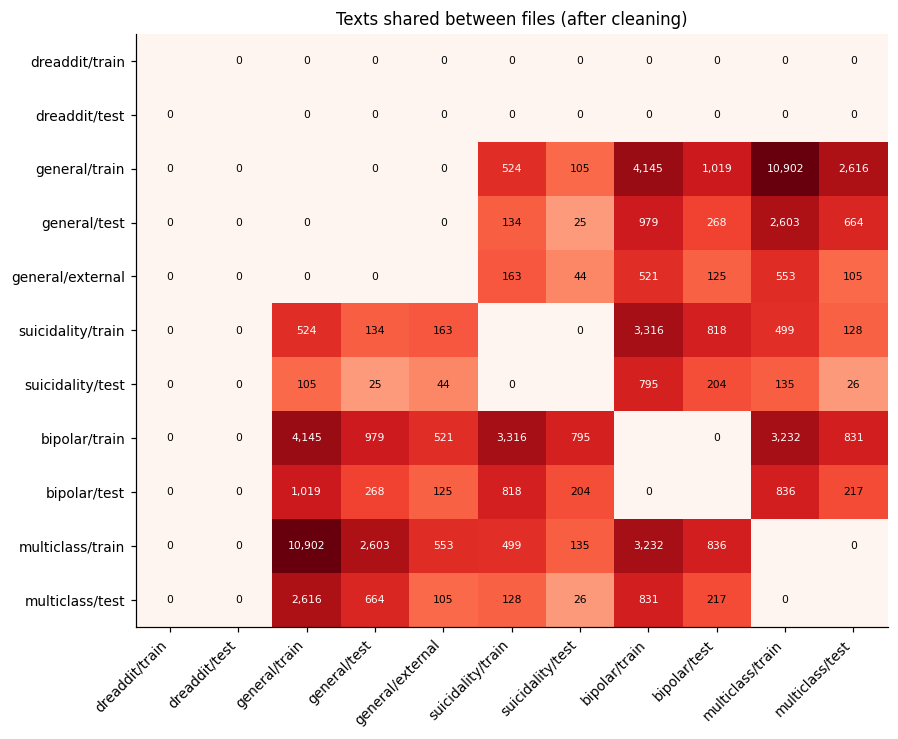

table saved: results/tables/cross_file_overlap.csv


In [9]:
names = [f"{t}/{s}" for t in TASKS_TO_RUN for s in DATA[t]]
hashes = {n: set(DATA[n.split("/")[0]][n.split("/")[1]]["h"]) for n in names}
overlap = pd.DataFrame([[len(hashes[a] & hashes[b]) if a != b else np.nan for b in names] for a in names],
                       index=names, columns=names)

fig, ax = plt.subplots(figsize=(0.62 * len(names) + 2, 0.5 * len(names) + 1.5))
vals = np.log1p(overlap.fillna(0).values)
ax.imshow(vals, cmap="Reds", aspect="auto")
for i in range(len(names)):
    for j in range(len(names)):
        v = overlap.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{int(v):,}", ha="center", va="center", fontsize=7,
                    color="white" if vals[i, j] > vals.max() * 0.6 else "black")
ax.set_xticks(range(len(names)), names, rotation=45, ha="right")
ax.set_yticks(range(len(names)), names)
ax.set_title("Texts shared between files (after cleaning)")
savefig(fig, "fig_01_cross_file_overlap"); plt.show()
save_table(overlap, "cross_file_overlap")

### 2.1b Do the tasks agree with each other?

Because the tasks share many posts, their labels can be checked against each other. A post labelled *control* in the general task should be *Control* in the multi-class task, and a post that is positive in the bipolar task should be *bipolar* in the multi-class task. All tasks derive their labels from the community a post was collected from, so a disagreement most plausibly means that the same text was collected from different communities - independent evidence, alongside the label conflicts of §2, that the labels record *where* a text was posted rather than *what* it says.

In [10]:
def labelled(task):
    df = pd.concat([DATA[task][s] for s in DATA[task]], ignore_index=True)
    names = dict(enumerate(SPEC[task]["label_names"]))
    return df.assign(name=df["label"].map(names))[["h", "label", "name"]].drop_duplicates("h")

mc = labelled("multiclass")
mc_control = mc["name"].str.lower() == "control"
mc = mc.assign(mc_control=mc_control, mc_bipolar=mc["name"].str.lower() == "bipolar")

g = labelled("general").merge(mc, on="h", suffixes=("_general", "_multiclass"))
b = labelled("bipolar").merge(mc, on="h", suffixes=("_bipolar", "_multiclass"))
agree_g = (g["label_general"] == 0) == g["mc_control"]     # general 0 = control (verified in 1.3)
agree_b = (b["label_bipolar"] == 1) == b["mc_bipolar"]     # bipolar 1 = bipolar  (verified in 1.3)

AGREEMENT = pd.DataFrame([
    {"pair": "general vs multiclass", "consistency rule": "general control  <->  multiclass Control",
     "shared posts": len(g), "agreement %": 100 * agree_g.mean() if len(g) else np.nan,
     "disagreements": int((~agree_g).sum())},
    {"pair": "bipolar vs multiclass", "consistency rule": "bipolar positive <->  multiclass bipolar",
     "shared posts": len(b), "agreement %": 100 * agree_b.mean() if len(b) else np.nan,
     "disagreements": int((~agree_b).sum())},
]).set_index("pair").round(2)
save_table(AGREEMENT, "cross_task_label_agreement")
display(AGREEMENT)
if len(g):
    display(Markdown("**Shared posts: general label (rows) vs multiclass label (columns)**"))
    display(pd.crosstab(g["name_general"], g["name_multiclass"]))
if len(b):
    display(Markdown("**Shared posts: bipolar label (rows) vs multiclass label (columns)**"))
    display(pd.crosstab(b["name_bipolar"], b["name_multiclass"]))

table saved: results/tables/cross_task_label_agreement.csv


,consistency rule,shared posts,agreement %,disagreements
pair,,,,
general vs multiclass,general control <-> multiclass Control,17443,100.0,0
bipolar vs multiclass,bipolar positive <-> multiclass bipolar,5116,100.0,0


**Shared posts: general label (rows) vs multiclass label (columns)**

name_multiclass,Control,adhd,anxiety,bipolar,cptsd,depression,schizophrenia
name_general,,,,,,,
Control,3811,0,0,0,0,0,0
Mental,0,580,1151,1382,4479,702,5338


**Shared posts: bipolar label (rows) vs multiclass label (columns)**

name_multiclass,Control,anxiety,bipolar,depression
name_bipolar,,,,
bipolar,0,0,3386,0
non-bipolar,876,512,0,342


### 2.2 Cross-corpus contamination: Dreaddit inside Hasan & Saquer

Both corpora were collected from Reddit and share communities such as r/anxiety and r/ptsd, so the same writing could appear in both. Because Dreaddit stores *excerpts* of posts rather than whole posts, exact hashing cannot detect this. Instead, three 10-word windows are taken from each Dreaddit segment and searched for inside every post of the *general* task.

Two kinds of contamination would bias the transfer study, and both are removed from the **evaluation** sets:

- Dreaddit **test** segments that occur inside *general* **training** posts (a general-trained model would have seen them);
- *general* **evaluation** posts that contain Dreaddit **training** segments (a Dreaddit-trained model would have seen them).

In [11]:
SHINGLE = 10
def tokens(text):
    return re.findall(r"[a-z0-9']+", text.lower())

def probes(text):
    t = tokens(text)
    if len(t) < SHINGLE:
        return []
    starts = sorted({0, (len(t) - SHINGLE) // 2, len(t) - SHINGLE})
    return [" ".join(t[s:s + SHINGLE]) for s in starts]

CONTAMINATION = {}
if TRANSFER_ON:
    owner = {}
    for dsplit, df in DATA["dreaddit"].items():
        for i, text in enumerate(df["text"]):
            for p in probes(text):
                owner.setdefault(p, []).append((dsplit, i))

    dd_hits = {s: set() for s in DATA["dreaddit"]}           # dreaddit rows found in general/train
    hs_hits = {s: set() for s in DATA["general"]}            # general rows containing dreaddit/train
    t0 = time.time()
    for gsplit, df in DATA["general"].items():
        for j, text in enumerate(df["text"]):
            t = tokens(text)
            for s in range(len(t) - SHINGLE + 1):
                for dsplit, i in owner.get(" ".join(t[s:s + SHINGLE]), ()):
                    if gsplit == "train":
                        dd_hits[dsplit].add(i)
                    if dsplit == "train":
                        hs_hits[gsplit].add(j)
    print(f"scanned {sum(len(d) for d in DATA['general'].values()):,} posts in {time.time() - t0:.0f}s")

    CONTAMINATION = {"dreaddit/test found in general/train": len(dd_hits["test"]),
                     "dreaddit/train found in general/train": len(dd_hits["train"])}
    for gsplit in DATA["general"]:
        if gsplit != "train":
            CONTAMINATION[f"general/{gsplit} containing dreaddit/train"] = len(hs_hits[gsplit])
            DATA["general"][gsplit] = DATA["general"][gsplit].drop(index=list(hs_hits[gsplit])).reset_index(drop=True)
    DATA["dreaddit"]["test"] = DATA["dreaddit"]["test"].drop(index=list(dd_hits["test"])).reset_index(drop=True)
    display(pd.Series(CONTAMINATION, name="segments / posts").to_frame())
    print("Contaminated evaluation items have been removed. Training items are left untouched.")
else:
    print("Cross-dataset study disabled -- check skipped.")

scanned 143,649 posts in 26s


,segments / posts
dreaddit/test found in general/train,8
dreaddit/train found in general/train,32
general/test containing dreaddit/train,7
general/external containing dreaddit/train,4


Contaminated evaluation items have been removed. Training items are left untouched.


## 3. Exploratory data analysis

### 3.1 Dataset summary

In [12]:
def pretty_names(task):
    names = SPEC[task]["label_names"]
    if SPEC[task]["kind"] == "binary" and names in (["0", "1"], ["False", "True"]):
        return [f"negative ({names[0]})", f"positive ({names[1]})"]
    return names

rows = []
for task in TASKS_TO_RUN:
    tr = DATA[task]["train"]
    words = tr["text"].str.split().str.len()
    shares = tr["label"].value_counts(normalize=True)
    rows.append({"task": task, "classes": SPEC[task]["k"], "train": len(tr),
                 **{f"eval: {s}": len(d) for s, d in DATA[task].items() if s != "train"},
                 "minority class %": round(100 * shares.min(), 1),
                 "median words": int(words.median()), "p95 words": int(words.quantile(0.95)),
                 "% > 200 words": round(100 * (words > 200).mean(), 1)})
summary = pd.DataFrame(rows).set_index("task").fillna("")
save_table(summary, "dataset_summary")
summary

table saved: results/tables/dataset_summary.csv


,classes,train,eval: test,minority class %,median words,p95 words,% > 200 words,eval: external
task,,,,,,,,
dreaddit,2,2817,704,47.4,80,143,0.7,
general,2,95753,23899,49.9,122,618,31.0,23986.0
suicidality,2,30177,7536,49.1,128,559,31.2,
bipolar,2,40056,10006,46.7,121,470,26.6,
multiclass,7,83966,20982,14.3,159,683,39.6,


The last column is an early warning for the transformer experiments: posts much longer than about 200 words exceed the `MAX_LENGTH` of 256 sub-word tokens and are truncated. The exact truncation rate is measured on the real tokeniser in §6.

figure saved: figures/fig_02_class_distribution.png


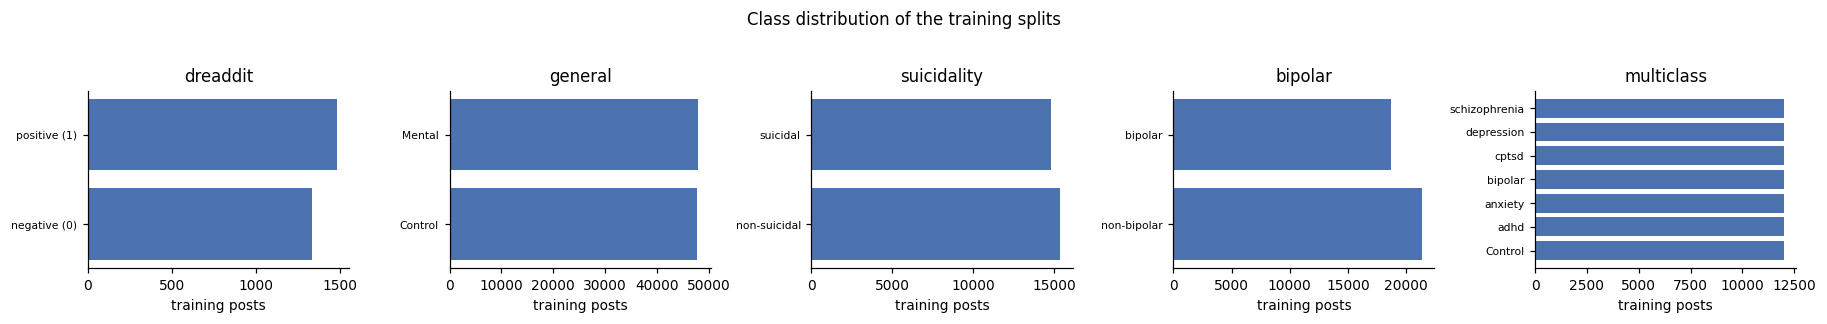

figure saved: figures/fig_03_length_by_class.png


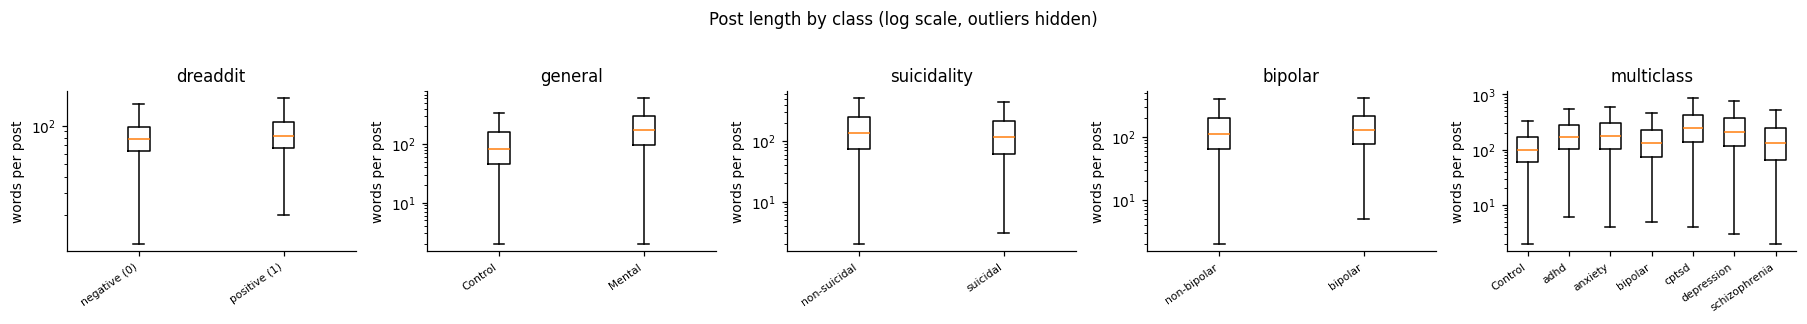

In [13]:
fig, axes = plt.subplots(1, len(TASKS_TO_RUN), figsize=(3.3 * len(TASKS_TO_RUN), 2.8))
axes = np.atleast_1d(axes)
for ax, task in zip(axes, TASKS_TO_RUN):
    counts = DATA[task]["train"]["label"].value_counts().sort_index()
    ax.barh([pretty_names(task)[i] for i in counts.index], counts.values, color="#4C72B0")
    ax.set_title(task); ax.set_xlabel("training posts")
    ax.tick_params(axis="y", labelsize=7)
fig.suptitle("Class distribution of the training splits", y=1.03)
fig.tight_layout(); savefig(fig, "fig_02_class_distribution"); plt.show()

fig, axes = plt.subplots(1, len(TASKS_TO_RUN), figsize=(3.3 * len(TASKS_TO_RUN), 2.8))
axes = np.atleast_1d(axes)
for ax, task in zip(axes, TASKS_TO_RUN):
    tr = DATA[task]["train"]
    groups = [tr.loc[tr["label"] == c, "text"].str.split().str.len().clip(lower=1)
              for c in range(SPEC[task]["k"])]
    ax.boxplot(groups, showfliers=False)
    ax.set_xticks(range(1, SPEC[task]["k"] + 1), pretty_names(task), rotation=35, ha="right", fontsize=7)
    ax.set_yscale("log"); ax.set_title(task); ax.set_ylabel("words per post")
fig.suptitle("Post length by class (log scale, outliers hidden)", y=1.03)
fig.tight_layout(); savefig(fig, "fig_03_length_by_class"); plt.show()

### 3.2 Linguistic markers

Two markers with an established clinical literature are measured by class: the rate of **first-person singular pronouns**, repeatedly found to be elevated in depression [7], and the rate of **absolutist words** (*always, never, completely, nothing*…), identified as a marker specific to anxiety, depression and suicidal ideation [8]. The share of posts containing a **URL** is included as a non-psychological contrast.

These markers cut both ways. Differences between classes confirm that the corpora carry the expected psychological signal - but they are also regularities of *style* that a classifier can exploit without modelling anything clinically meaningful. That tension is quantified directly in §7.2.

table saved: results/tables/linguistic_markers.csv
figure saved: figures/fig_04_linguistic_markers.png


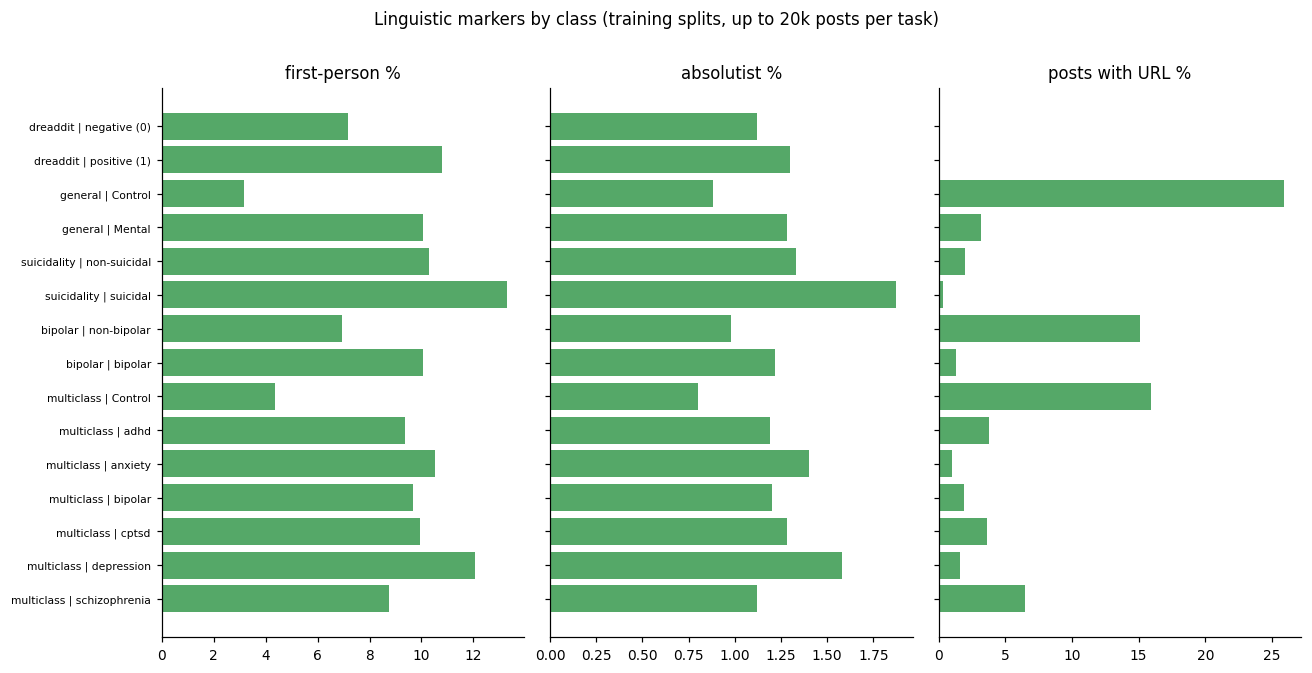

first-person %  absolutist %  posts with URL %
task        class                                                        
dreaddit    negative (0)             7.17          1.12               0.1
            positive (1)            10.78          1.30               0.0
general     Control                  3.17          0.88              25.9
            Mental                  10.05          1.28               3.2
suicidality non-suicidal            10.30          1.33               2.0
            suicidal                13.29          1.87               0.3
bipolar     non-bipolar              6.95          0.98              15.1
            bipolar                 10.05          1.22               1.3
multiclass  Control                  4.38          0.80              15.9
            adhd                     9.36          1.19               3.8
            anxiety                 10.52          1.40               1.0
            bipolar                  9.66          1.20               1.9
            cptsd                    9.93          1.28               3.6
            depression              12.07          1.58               1.6
            schizophrenia            8.74          1.12               6.5

In [14]:
FIRST_PERSON = {"i", "me", "my", "mine", "myself", "i'm", "im", "i've", "ive", "i'd", "i'll"}
ABSOLUTIST = {"absolutely", "all", "always", "complete", "completely", "constant", "constantly",
              "definitely", "entire", "ever", "every", "everyone", "everything", "full", "must",
              "never", "nothing", "totally", "whole"}          # the 19-word list of [8]
URL_RE = re.compile(r"https?://\S+|www\.\S+")

def marker_rates(texts):
    fp, ab, url = [], [], []
    for t in texts:
        toks = re.findall(r"[a-z']+", t.lower())
        n = max(len(toks), 1)
        fp.append(100 * sum(x in FIRST_PERSON for x in toks) / n)
        ab.append(100 * sum(x in ABSOLUTIST for x in toks) / n)
        url.append(100.0 * bool(URL_RE.search(t)))
    return np.mean(fp), np.mean(ab), np.mean(url)

rows = []
for task in TASKS_TO_RUN:
    tr = DATA[task]["train"]
    sample = tr.sample(min(len(tr), 20_000), random_state=SEED)
    for c in range(SPEC[task]["k"]):
        fp, ab, url = marker_rates(sample.loc[sample["label"] == c, "text"])
        rows.append({"task": task, "class": pretty_names(task)[c],
                     "first-person %": round(fp, 2), "absolutist %": round(ab, 2),
                     "posts with URL %": round(url, 1)})
markers = pd.DataFrame(rows).set_index(["task", "class"])
save_table(markers, "linguistic_markers")

fig, axes = plt.subplots(1, 3, figsize=(12, 0.32 * len(markers) + 1.2), sharey=True)
labels = [f"{t} | {c}" for t, c in markers.index]
for ax, col in zip(axes, markers.columns):
    ax.barh(labels, markers[col].values, color="#55A868")
    ax.set_title(col); ax.invert_yaxis(); ax.tick_params(axis="y", labelsize=7)
fig.suptitle("Linguistic markers by class (training splits, up to 20k posts per task)", y=1.01)
fig.tight_layout(); savefig(fig, "fig_04_linguistic_markers"); plt.show()
markers

## 4. Evaluation framework

**Primary metric: macro-F1.** The unweighted mean of per-class F1. Unlike accuracy it cannot be inflated by favouring a majority class, and it weights every condition equally in the multi-class task.

**AUROC** (binary) and **macro one-vs-rest AUROC** (multi-class). Threshold-independent: it measures how well the model *ranks* positive above negative cases. This matters most in §8. When a model is moved to new data, its scores may still rank cases correctly while the fixed decision threshold of 0.5 no longer fits; macro-F1 then collapses while AUROC holds. The two metrics together separate a failure of *ranking* (the model no longer orders positive above negative posts) from a failure of *calibration* (the ranking survives but the threshold no longer fits).

**Sensitivity and specificity** of the positive class are reported for the binary tasks, because in a screening setting a missed case (false negative) and a false alarm (false positive) carry very different costs.

**Uncertainty.** Every score carries a 95% **bootstrap confidence interval** over test examples (1,000 resamples). Model comparisons use the **paired bootstrap** test of Berg-Kirkpatrick et al. [9], as recommended for NLP by Dror et al. [10]: both models are rescored on the same resamples, which controls for the difficulty of individual examples. Because many comparisons are made, their *p*-values are adjusted with the Holm–Bonferroni procedure [19].

All metrics are computed from confusion matrices with vectorised NumPy, so that thousands of bootstrap resamples remain fast on large test sets.

In [15]:
def confusion(y, pred, k):
    return np.bincount(y * k + pred, minlength=k * k).reshape(k, k)

def macro_f1_cm(cm):
    tp = np.diag(cm).astype(float)
    denom = 2 * tp + (cm.sum(0) - tp) + (cm.sum(1) - tp)
    return np.divide(2 * tp, denom, out=np.zeros_like(tp), where=denom > 0).mean()

def evaluate(y, probs, k):
    y = np.asarray(y); pred = probs.argmax(1)
    cm = confusion(y, pred, k)
    tp, support, predicted = np.diag(cm), cm.sum(1), cm.sum(0)
    m = {"n": int(len(y)), "macro_f1": float(macro_f1_cm(cm)),
         "accuracy": float(tp.sum() / max(len(y), 1)),
         "recall": np.divide(tp, support, out=np.zeros(k), where=support > 0).tolist(),
         "precision": np.divide(tp, predicted, out=np.zeros(k), where=predicted > 0).tolist(),
         "confusion": cm.tolist(), "auroc": None}
    if len(np.unique(y)) == k:
        try:
            m["auroc"] = float(roc_auc_score(y, probs[:, 1]) if k == 2 else
                               roc_auc_score(y, probs, multi_class="ovr", average="macro"))
        except ValueError:
            pass
    return m

def bootstrap_ci(y, pred, k, n=N_BOOTSTRAP, seed=SEED):
    rng = np.random.default_rng(seed); N = len(y)
    stats = np.array([macro_f1_cm(confusion(y[i], pred[i], k))
                      for i in (rng.integers(0, N, N) for _ in range(n))])
    a = (1 - CI_LEVEL) / 2
    return np.quantile(stats, [a, 1 - a])

def paired_bootstrap(y, pred_a, pred_b, k, n=N_BOOTSTRAP, seed=SEED):
    """Macro-F1(a) - macro-F1(b): observed difference, CI, and the one-sided
    p-value of Berg-Kirkpatrick et al. (2012) for H0: a is not better than b."""
    rng = np.random.default_rng(seed); N = len(y)
    f = lambda yy, pp: macro_f1_cm(confusion(yy, pp, k))
    obs = f(y, pred_a) - f(y, pred_b)
    d = np.empty(n)
    for b in range(n):
        i = rng.integers(0, N, N)
        d[b] = f(y[i], pred_a[i]) - f(y[i], pred_b[i])
    a = (1 - CI_LEVEL) / 2
    lo, hi = np.quantile(d, [a, 1 - a])
    p = float(np.mean(d >= 2 * obs)) if obs > 0 else float(np.mean(d <= 2 * obs))
    return obs, lo, hi, p

# ------------------------------------------------------------------ experiment cache
def run_file(run_id):
    return CACHE_DIR / f"{run_id}.json"

def pred_file(run_id, eval_name):
    return CACHE_DIR / "preds" / f"{run_id}__{eval_name.replace('/', '-')}.npz"

def fingerprint(task, **settings):
    """Hash of the exact training/evaluation data plus the settings of a run.
    A cached result is reused only if its fingerprint matches, so changing the
    cleaning, the data or a hyper-parameter can never silently reuse stale results."""
    parts = [f"train:{hashlib.md5(''.join(sorted(DATA[task]['train']['h'])).encode()).hexdigest()}"]
    for e in eval_sets(task):
        parts.append(f"{e}:{hashlib.md5(''.join(sorted(get_eval(e)['h'])).encode()).hexdigest()}")
    parts.append(json.dumps(settings, sort_keys=True, default=str))
    return hashlib.md5("|".join(parts).encode()).hexdigest()[:16]

def is_done(run_id, fp):
    if FORCE_RERUN or not run_file(run_id).exists():
        return False
    return json.loads(run_file(run_id).read_text()).get("fingerprint") == fp

def save_run(record, preds):
    for e, (y, probs) in preds.items():          # predictions first ...
        np.savez_compressed(pred_file(record["run_id"], e), y=y, probs=probs.astype(np.float32))
    run_file(record["run_id"]).write_text(json.dumps(record, indent=2))   # ... then the record

def load_runs():
    return {p.stem: json.loads(p.read_text()) for p in sorted(CACHE_DIR.glob("*.json"))}

def load_preds(run_id, eval_name):
    z = np.load(pred_file(run_id, eval_name))
    return z["y"], z["probs"]

def eval_sets(task):
    names = [f"{task}/{s}" for s in DATA[task] if s != "train"]
    if TRANSFER_ON and task in TRANSFER_GROUP:
        names += [e for e in TRANSFER_EVAL if e not in names]
    return names

def get_eval(name):
    task, split = name.split("/")
    return DATA[task][split]

# sanity check against scikit-learn
from sklearn.metrics import f1_score
_rng = np.random.default_rng(0); _y = _rng.integers(0, 4, 500); _p = _rng.integers(0, 4, 500)
assert abs(macro_f1_cm(confusion(_y, _p, 4)) - f1_score(_y, _p, average="macro")) < 1e-12
print("metric implementation verified against scikit-learn")

metric implementation verified against scikit-learn


## 5. Classical models

Five classical models are trained on every task: two reference models and three lexical classifiers. Together they bracket what a transformer has to beat, and what part of its performance can be explained trivially.

| Model | Input | Role |
|---|---|---|
| **Majority** | none | the floor: always predicts the most frequent class |
| **Surface (shortcut probe)** | 8 stylistic features: length, token count, first-person rate, URLs, question and exclamation rates, capitalisation, line breaks | how far one gets *without reading what the post says* |
| **TF-IDF + logistic regression** (`tfidf`) | word uni- and bi-grams, 50k features, sublinear term frequency | a strong, interpretable lexical baseline |
| **TF-IDF + linear SVM** (`svm`) | same features | the classic text-classification model [15], among the most frequently used in this literature |
| **TF-IDF + multinomial Naive Bayes** (`nb`) | same features | the other long-standing text baseline [16] |

Logistic regression and the SVM use balanced class weights, so no model can succeed merely by leaning on the majority class. A linear SVM outputs margins rather than probabilities; they are mapped to probabilities with Platt scaling [17], fitted by 3-fold cross-validation inside the training set, so that AUROC and every analysis of §8 apply to the SVM unchanged. All three lexical models share identical features, so differences between them isolate the learning algorithm. Tree ensembles (random forest, gradient boosting) are not included: on sparse, 50,000-dimensional text representations they are slow and are consistently outperformed by linear models.

In [16]:
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

SURFACE_NAMES = ["n_chars", "n_tokens", "first_person_rate", "n_urls",
                 "question_rate", "exclaim_rate", "uppercase_rate", "n_newlines"]

def surface_features(texts):
    rows = []
    for text in texts:
        toks = re.findall(r"[a-z']+", text.lower())
        n = max(len(toks), 1)
        rows.append([len(text), n, sum(t in FIRST_PERSON for t in toks) / n,
                     len(URL_RE.findall(text)), text.count("?") / n, text.count("!") / n,
                     sum(c.isupper() for c in text) / max(len(text), 1), text.count("\n")])
    return np.asarray(rows, dtype=float)

from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.calibration import CalibratedClassifierCV

TFIDF = dict(max_features=50_000, ngram_range=(1, 2), min_df=2, sublinear_tf=True, strip_accents="unicode")
# Every hyper-parameter is recorded here and enters the cache fingerprint, so changing one
# can never silently reuse results computed with the old setting.
CLASSICAL_SPECS = {
    "majority": {"strategy": "most_frequent"},
    "surface":  {"features": SURFACE_NAMES, "C": 1.0},
    "tfidf":    {"tfidf": TFIDF, "C": 1.0},
    "svm":      {"tfidf": TFIDF, "C": 1.0, "calibration": "sigmoid", "cv": 3},
    "nb":       {"tfidf": TFIDF, "alpha": 1.0},
}

def make_classical(name):
    spec = CLASSICAL_SPECS[name]
    lr = dict(max_iter=2000, class_weight="balanced", random_state=SEED)
    if name == "majority":
        return DummyClassifier(strategy=spec["strategy"])
    if name == "surface":
        return make_pipeline(FunctionTransformer(surface_features), StandardScaler(),
                             LogisticRegression(C=spec["C"], **lr))
    if name == "tfidf":
        return make_pipeline(TfidfVectorizer(**spec["tfidf"]), LogisticRegression(C=spec["C"], **lr))
    if name == "svm":
        svm = LinearSVC(C=spec["C"], class_weight="balanced", max_iter=5000, random_state=SEED)
        return make_pipeline(TfidfVectorizer(**spec["tfidf"]),
                             CalibratedClassifierCV(svm, method=spec["calibration"], cv=spec["cv"]))
    if name == "nb":
        return make_pipeline(TfidfVectorizer(**spec["tfidf"]), MultinomialNB(alpha=spec["alpha"]))
    raise ValueError(name)

CLASSICAL_MODELS = ["majority", "surface", "tfidf", "svm", "nb"]

def aligned_proba(model, texts, k):
    out = np.zeros((len(texts), k))
    out[:, model.classes_] = model.predict_proba(texts)
    return out

def top_terms(pipe, names, n=25):
    vec, clf = pipe.steps[0][1], pipe.steps[-1][1]
    vocab = np.array(vec.get_feature_names_out())
    if clf.coef_.shape[0] == 1:
        order = np.argsort(clf.coef_[0])
        return {names[1]: vocab[order[-n:]][::-1].tolist(), names[0]: vocab[order[:n]].tolist()}
    return {names[c]: vocab[np.argsort(clf.coef_[c])[-n:]][::-1].tolist()
            for c in range(clf.coef_.shape[0])}

In [17]:
if RUN_CLASSICAL:
    for task in TASKS_TO_RUN:
        tr, k = DATA[task]["train"], SPEC[task]["k"]
        for name in CLASSICAL_MODELS:
            run_id = f"{name}__{task}"
            fp = fingerprint(task, model=name, spec=CLASSICAL_SPECS[name], seed=SEED, min_chars=MIN_CHARS)
            if is_done(run_id, fp):
                print(f"[cached] {run_id}"); continue
            t0 = time.time()
            model = make_classical(name).fit(tr["text"].tolist(), tr["label"].to_numpy())
            fit_s = time.time() - t0
            preds, metrics = {}, {}
            for e in eval_sets(task):
                ev = get_eval(e)
                probs = aligned_proba(model, ev["text"].tolist(), k)
                preds[e] = (ev["label"].to_numpy(), probs)
                metrics[e] = evaluate(ev["label"].to_numpy(), probs, k)
            record = {"run_id": run_id, "fingerprint": fp, "family": "classical", "model": name, "task": task,
                      "k": k, "labels": pretty_names(task), "n_train": len(tr), "seed": SEED,
                      "fit_seconds": round(fit_s, 1), "metrics": metrics}
            if name == "tfidf":
                record["top_terms"] = top_terms(model, pretty_names(task))
            save_run(record, preds)
            own = metrics[f"{task}/test"]
            auc = f"{own['auroc']:.3f}" if own["auroc"] is not None else "  -  "
            print(f"{run_id:<24} fit {fit_s:6.1f}s | in-domain macro-F1 {own['macro_f1']:.3f} | AUROC {auc}")
else:
    print("Classical experiments skipped (RUN_CLASSICAL = False).")

[cached] majority__dreaddit
[cached] surface__dreaddit
[cached] tfidf__dreaddit
[cached] svm__dreaddit
[cached] nb__dreaddit
[cached] majority__general
[cached] surface__general
[cached] tfidf__general
[cached] svm__general
[cached] nb__general
[cached] majority__suicidality
[cached] surface__suicidality
[cached] tfidf__suicidality
[cached] svm__suicidality
[cached] nb__suicidality
[cached] majority__bipolar
[cached] surface__bipolar
[cached] tfidf__bipolar
[cached] svm__bipolar
[cached] nb__bipolar
[cached] majority__multiclass
[cached] surface__multiclass
[cached] tfidf__multiclass
[cached] svm__multiclass
[cached] nb__multiclass


### 5.1 Most predictive terms

The highest-weighted n-grams show *what* the lexical model relies on. Clinically meaningful terms (symptoms, medication, diagnosis) indicate genuine signal; terms that merely identify the topic of a control community (sport, politics, travel) indicate a **shortcut** - the model is separating communities rather than mental states. Both kinds will usually appear; their balance is the point of interest.

In [18]:
runs = load_runs()
for task in TASKS_TO_RUN:
    r = runs.get(f"tfidf__{task}")
    if not r:
        continue
    tbl = pd.DataFrame({cls: terms[:12] for cls, terms in r["top_terms"].items()})
    display(Markdown(f"**{task}** — top 12 terms per class"))
    display(tbl)

**dreaddit** — top 12 terms per class

,positive (1),negative (0)
0,me,you
1,my,we
2,feel,her
3,even,your
4,because,url
5,just,she
6,am,met
7,anxiety,more
8,don,would
9,what to,for


**general** — top 12 terms per class

,Mental,Control
0,adhd,confidence
1,schizophrenia,bike
2,bipolar,confident
3,anxiety,tour
4,depression,touring
5,my,obama
6,manic,sports
7,schizophrenic,politics
8,ptsd,the
9,meds,http


**suicidality** — top 12 terms per class

,suicidal,non-suicidal
0,suicide,bipolar
1,suicidal,manic
2,die,anxiety
3,kill,episode
4,kill myself,social
5,life,mania
6,end,meds
7,pain,social anxiety
8,to die,anxious
9,attempt,sa


**bipolar** — top 12 terms per class

,bipolar,non-bipolar
0,bipolar,anxiety
1,manic,my depression
2,mania,panic
3,lithium,travel
4,episode,trip
5,hypomanic,confidence
6,hypomania,bike
7,depressed,anxious
8,meds,flight
9,seroquel,depression


**multiclass** — top 12 terms per class

,Control,adhd,anxiety,bipolar,cptsd,depression,schizophrenia
0,travel,adhd,anxiety,bipolar,ptsd,depression,schizophrenia
1,trip,adderall,panic,manic,flashbacks,my depression,schizophrenic
2,confidence,vyvanse,anxious,mania,cptsd,antidepressants,psychosis
3,traveling,add,gad,lithium,trauma,with depression,delusions
4,obama,concerta,overthinking,hypomanic,dissociation,hate myself,hallucinations
5,tour,ritalin,attack,depressed,nightmares,suicidal thoughts,voices
6,bike,with adhd,panic attack,hypomania,emdr,depressed,paranoia
7,politics,my adhd,xanax,lamotrigine,abuse,suicidal,antipsychotics
8,the,adhd and,freaking out,episode,emotional,self harm,abilify
9,flight,overwhelmed,my anxiety,seroquel,hypervigilance,suicide,schizo


## 6. Transformer fine-tuning

A pretrained encoder (RoBERTa-base [3] by default) is fine-tuned separately for each task with a classification head. Design choices, each of which should be stated in the Methodology chapter:

- **Validation.** 10% of the *training* split, stratified by class, is held out. The best epoch is selected on validation macro-F1. The test sets are never used for any decision, so reported test scores are unbiased.
- **Optimisation.** AdamW [13] with weight decay 0.01, learning rate 2·10⁻⁵, linear warm-up over the first 6% of steps followed by linear decay, gradient clipping at 1.0 - the standard fine-tuning recipe of the BERT/RoBERTa literature.
- **Efficiency.** Mixed precision (fp16) on the GPU; dynamic padding; evaluation batches sorted by length.
- **Input length.** Posts are truncated to `MAX_LENGTH` = 256 sub-word tokens; the truncation rate is recorded for every split.
- **Implementation.** A plain PyTorch training loop with manual padding and scheduling rather than the Hugging Face `Trainer`, so that no behaviour is hidden and the code does not depend on library APIs that change between releases.
- **Domain-adapted models.** MentalRoBERTa [4], pretrained on mental-health Reddit text, can be added to `TRANSFORMER_MODELS` after requesting access on Hugging Face (`huggingface-cli login`).

Every run is cached immediately after it finishes.

In [19]:
if RUN_TRANSFORMERS:
    import torch
    from torch.utils.data import DataLoader
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    from sklearn.model_selection import train_test_split
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("device:", DEVICE, f"({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "")

class Encoded:
    """Map-style dataset of token-id lists; DataLoader needs only __len__/__getitem__."""
    def __init__(self, ids, labels):
        self.ids, self.labels = ids, np.asarray(labels)
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        return self.ids[i], int(self.labels[i])

def make_collate(pad_id):
    def collate(batch):
        L = max(len(s) for s, _ in batch)
        ids = torch.full((len(batch), L), pad_id, dtype=torch.long)
        mask = torch.zeros((len(batch), L), dtype=torch.long)
        for i, (s, _) in enumerate(batch):
            ids[i, :len(s)] = torch.tensor(s, dtype=torch.long)
            mask[i, :len(s)] = 1
        return ids, mask, torch.tensor([y for _, y in batch], dtype=torch.long)
    return collate

def encode(tokenizer, texts, labels):
    ids = tokenizer(list(texts), truncation=True, max_length=MAX_LENGTH)["input_ids"]
    truncated = float(np.mean([len(s) >= MAX_LENGTH for s in ids])) if len(ids) else 0.0
    return Encoded(ids, labels), truncated

def autocast():
    return (torch.autocast("cuda", dtype=torch.float16) if DEVICE.type == "cuda"
            else contextlib.nullcontext())

def make_scaler():
    on = DEVICE.type == "cuda"
    try:
        return torch.amp.GradScaler("cuda", enabled=on)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=on)

def predict_probs(model, ds, collate):
    model.eval()
    order = np.argsort([len(s) for s in ds.ids])
    out = np.zeros((len(ds), model.config.num_labels), dtype=np.float32)
    with torch.no_grad():
        for start in range(0, len(order), EVAL_BATCH):
            idx = order[start:start + EVAL_BATCH]
            ids, mask, _ = collate([ds[int(i)] for i in idx])
            with autocast():
                logits = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE)).logits
            out[idx] = torch.softmax(logits.float(), dim=-1).cpu().numpy()
    return out

def fine_tune(task, model_name, seed=SEED, max_train=None, epochs=None, verbose=True, track_train=False):
    set_seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    k = SPEC[task]["k"]
    data = DATA[task]["train"]
    if max_train and max_train < len(data):
        data, _ = train_test_split(data, train_size=max_train, stratify=data["label"], random_state=seed)
    tr, va = train_test_split(data, test_size=VAL_FRAC, stratify=data["label"], random_state=seed)

    tok = AutoTokenizer.from_pretrained(model_name)
    collate = make_collate(tok.pad_token_id if tok.pad_token_id is not None else 0)
    tr_ds, tr_trunc = encode(tok, tr["text"], tr["label"])
    va_ds, _ = encode(tok, va["text"], va["label"])
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=k).to(DEVICE)

    loader = DataLoader(tr_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate,
                        generator=torch.Generator().manual_seed(seed))
    epochs = epochs or EPOCHS.get(task, EPOCHS["default"])
    total = epochs * len(loader); warm = max(1, int(WARMUP_FRAC * total))
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: s / warm if s < warm else max(0.0, (total - s) / max(1, total - warm)))
    scaler, loss_fn = make_scaler(), torch.nn.CrossEntropyLoss()

    history, best_f1, best_state, best_epoch, t_start = [], -1.0, None, 0, time.time()
    for epoch in range(1, epochs + 1):
        model.train(); t0, run_loss = time.time(), 0.0
        for step, (ids, mask, y) in enumerate(loader, 1):
            ids, mask, y = ids.to(DEVICE), mask.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with autocast():
                logits = model(input_ids=ids, attention_mask=mask).logits
            loss = loss_fn(logits.float(), y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run_loss += loss.item()
            if verbose and epoch == 1 and step == 50:
                per = (time.time() - t0) / 50
                print(f"    ~{per * len(loader) / 60:.1f} min/epoch, ~{per * total / 60:.1f} min training in total")
            if verbose and step % 500 == 0:
                print(f"    epoch {epoch} step {step:>6}/{len(loader)} loss {run_loss / step:.4f}")
        vm = evaluate(va_ds.labels, predict_probs(model, va_ds, collate), k)
        history.append({"epoch": epoch, "train_loss": run_loss / len(loader),
                        "val_macro_f1": vm["macro_f1"], "val_auroc": vm["auroc"]})
        if track_train:   # optional, used only by the overfitting check of §7.5
            history[-1]["train_macro_f1"] = evaluate(tr_ds.labels, predict_probs(model, tr_ds, collate), k)["macro_f1"]
        if verbose:
            print(f"    epoch {epoch}: {(time.time() - t0) / 60:.1f} min | train loss {run_loss / len(loader):.4f}"
                  f" | val macro-F1 {vm['macro_f1']:.4f}")
        if vm["macro_f1"] > best_f1:
            best_f1, best_epoch = vm["macro_f1"], epoch
            best_state = {n: v.detach().cpu().clone() for n, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    info = {"n_train": len(tr), "n_val": len(va), "history": history, "best_epoch": best_epoch,
            "best_val_macro_f1": best_f1, "train_truncated": tr_trunc,
            "train_minutes": round((time.time() - t_start) / 60, 1)}
    return model, tok, collate, info

device: cuda (Tesla T4)


### 6.1 Smoke test

Before committing GPU time to the full runs, the entire training and prediction path is exercised on 300 examples for one epoch. It takes one to two minutes and catches configuration errors - a wrong model name, a GPU that was not allocated, an out-of-memory batch size - before they cost half an hour.

In [20]:
if RUN_TRANSFORMERS and SMOKE_TEST_FIRST:
    t0 = time.time()
    smoke_task = "dreaddit" if "dreaddit" in TASKS_TO_RUN else TASKS_TO_RUN[0]
    m, tok, collate, info = fine_tune(smoke_task, TRANSFORMER_MODELS[0], max_train=300, epochs=1, verbose=False)
    ev = DATA[smoke_task]["test"].head(200)
    ds, _ = encode(tok, ev["text"], ev["label"])
    p = predict_probs(m, ds, collate)
    assert p.shape == (len(ds), SPEC[smoke_task]["k"]) and np.allclose(p.sum(1), 1, atol=1e-3)
    print(f"SMOKE TEST PASSED in {time.time() - t0:.0f}s -- the full runs can start.")
    del m; gc.collect(); torch.cuda.empty_cache()
else:
    print("Smoke test skipped.")

Smoke test skipped.


### 6.2 Full runs

Tasks run in order of increasing cost (Dreaddit first), so that the most informative results arrive early and a disconnection costs as little as possible. On a Colab T4, expect a few minutes for Dreaddit and roughly 10–35 minutes for each Hasan & Saquer task at full size; the exact estimate is printed after the first 50 steps of every run.

In [21]:
def run_transformer(task, model_name, seed):
    tag = model_name.split("/")[-1]
    run_id = f"{tag}__{task}__s{seed}" + (f"__n{TRANSFORMER_MAX_TRAIN}" if TRANSFORMER_MAX_TRAIN else "")
    settings = {"model": model_name, "seed": seed, "max_train": TRANSFORMER_MAX_TRAIN,
                "max_length": MAX_LENGTH, "batch_size": BATCH_SIZE, "lr": LR, "wd": WEIGHT_DECAY,
                "warmup": WARMUP_FRAC, "epochs": EPOCHS.get(task, EPOCHS["default"]),
                "val_frac": VAL_FRAC, "min_chars": MIN_CHARS}
    fp = fingerprint(task, **settings)
    if is_done(run_id, fp):
        print(f"[cached] {run_id}"); return
    print(f"\n>>> {run_id}")
    model, tok, collate, info = fine_tune(task, model_name, seed, TRANSFORMER_MAX_TRAIN)
    k, preds, metrics = SPEC[task]["k"], {}, {}
    for e in eval_sets(task):
        ev = get_eval(e)
        ds, trunc = encode(tok, ev["text"], ev["label"])
        probs = predict_probs(model, ds, collate)
        y = ev["label"].to_numpy()
        preds[e] = (y, probs)
        metrics[e] = {**evaluate(y, probs, k), "truncated": trunc}
    record = {"run_id": run_id, "fingerprint": fp, "family": "transformer", "model": tag, "task": task, "k": k,
              "labels": pretty_names(task), "seed": seed, "max_train": TRANSFORMER_MAX_TRAIN,
              "metrics": metrics, **info,
              "config": {"max_length": MAX_LENGTH, "batch_size": BATCH_SIZE, "lr": LR,
                         "weight_decay": WEIGHT_DECAY, "warmup_frac": WARMUP_FRAC,
                         "epochs": EPOCHS.get(task, EPOCHS["default"]), "val_frac": VAL_FRAC}}
    save_run(record, preds)
    own = metrics[f"{task}/test"]
    print(f"<<< {run_id}: in-domain macro-F1 {own['macro_f1']:.4f} | AUROC {own['auroc']:.4f} "
          f"| {info['train_minutes']} min")
    del model; gc.collect(); torch.cuda.empty_cache()

if RUN_TRANSFORMERS:
    for model_name in TRANSFORMER_MODELS:
        for seed in TRANSFORMER_SEEDS:
            for task in TASKS_TO_RUN:
                run_transformer(task, model_name, seed)
else:
    print("Transformer experiments skipped -- results below use the classical models only.")

[cached] roberta-base__dreaddit__s42
[cached] roberta-base__general__s42
[cached] roberta-base__suicidality__s42
[cached] roberta-base__bipolar__s42
[cached] roberta-base__multiclass__s42


figure saved: figures/fig_05_training_curves.png


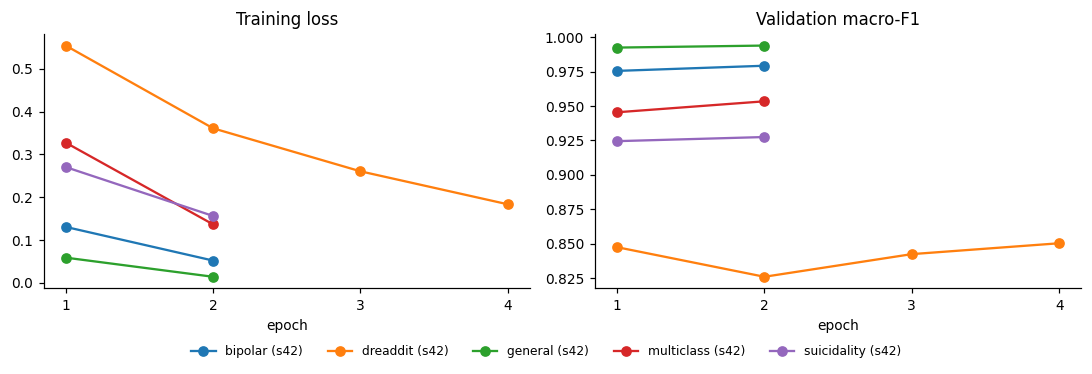

,best epoch,val macro-F1,train truncated %,minutes
run,,,,
roberta-base__bipolar__s42,2,0.9792,28.1,15.7
roberta-base__dreaddit__s42,4,0.8503,0.4,1.8
roberta-base__general__s42,2,0.9938,32.4,37.1
roberta-base__multiclass__s42,2,0.9534,40.0,33.5
roberta-base__suicidality__s42,2,0.9274,30.9,12.0


In [22]:
runs = load_runs()
tf_runs = [r for r in runs.values() if r["family"] == "transformer"]
if tf_runs:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
    for r in tf_runs:
        h = pd.DataFrame(r["history"])
        lbl = f"{r['task']} (s{r['seed']})"
        axes[0].plot(h["epoch"], h["train_loss"], marker="o", label=lbl)
        axes[1].plot(h["epoch"], h["val_macro_f1"], marker="o", label=lbl)
    from matplotlib.ticker import MaxNLocator
    axes[0].set(title="Training loss", xlabel="epoch")
    axes[1].set(title="Validation macro-F1", xlabel="epoch")
    for ax in axes:
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))   # epochs are whole numbers
    handles, labels = axes[1].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=len(labels), fontsize=8,
               bbox_to_anchor=(0.5, -0.06), frameon=False)        # below the plots: covers no data
    fig.tight_layout(); savefig(fig, "fig_05_training_curves"); plt.show()
    display(pd.DataFrame([{"run": r["run_id"], "best epoch": r["best_epoch"],
                           "val macro-F1": round(r["best_val_macro_f1"], 4),
                           "train truncated %": round(100 * r["train_truncated"], 1),
                           "minutes": r["train_minutes"]} for r in tf_runs]).set_index("run"))
else:
    print("No transformer runs in the cache yet.")

## 7. Results: in-domain performance (RQ1, RQ2)

All results below are read from the experiment cache, so this section can be re-run at any time without retraining. Where several transformer seeds exist, the main tables use the first seed in `TRANSFORMER_SEEDS`; seed variability is reported separately in §7.4.

In [23]:
RUNS = load_runs()
TF_TAGS = [m.split("/")[-1] for m in TRANSFORMER_MODELS]

def expected_fp(r):
    if r["family"] == "classical":
        return fingerprint(r["task"], model=r["model"], spec=CLASSICAL_SPECS.get(r["model"]),
                           seed=SEED, min_chars=MIN_CHARS)
    name = next(m for m in TRANSFORMER_MODELS if m.split("/")[-1] == r["model"])
    return fingerprint(r["task"], model=name, seed=r["seed"], max_train=TRANSFORMER_MAX_TRAIN,
                       max_length=MAX_LENGTH, batch_size=BATCH_SIZE, lr=LR, wd=WEIGHT_DECAY,
                       warmup=WARMUP_FRAC, epochs=EPOCHS.get(r["task"], EPOCHS["default"]),
                       val_frac=VAL_FRAC, min_chars=MIN_CHARS)

def is_current(r):
    if r["task"] not in TASKS_TO_RUN:
        return False
    if r["family"] == "transformer" and r["model"] not in TF_TAGS:
        return False
    return r.get("fingerprint") == expected_fp(r)

STALE = [rid for rid, r in RUNS.items() if r["task"] in TASKS_TO_RUN and not is_current(r)
         and not (r["family"] == "transformer" and r["model"] not in TF_TAGS)]
if STALE:
    print(f"[!] {len(STALE)} cached run(s) no longer match the current data/settings and are "
          f"excluded: {STALE}. Re-run §5/§6 to refresh them.")

MAIN = {rid: r for rid, r in RUNS.items() if is_current(r)
        and (r["family"] == "classical" or r["seed"] == TRANSFORMER_SEEDS[0])}
MODEL_ORDER = [m for m in CLASSICAL_MODELS + TF_TAGS if any(r["model"] == m for r in MAIN.values())]
TF_PRESENT = [m for m in MODEL_ORDER if m in TF_TAGS]
FOCUS = TF_PRESENT[0] if TF_PRESENT else "tfidf"     # model used for detailed figures

def run_of(model, task):
    return next((r for r in MAIN.values() if r["model"] == model and r["task"] == task), None)

def heatmap(ax, df, title, vmin=0.0, vmax=1.0, cmap="viridis", fmt="{:.3f}"):
    vals = df.values.astype(float)
    ax.imshow(vals, vmin=vmin, vmax=vmax, cmap=cmap, aspect="auto")
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            if not np.isnan(vals[i, j]):
                ax.text(j, i, fmt.format(vals[i, j]), ha="center", va="center", fontsize=8,
                        color="white" if vals[i, j] < vmin + 0.55 * (vmax - vmin) else "black")
    ax.set_xticks(range(vals.shape[1]), df.columns, rotation=30, ha="right")
    ax.set_yticks(range(vals.shape[0]), df.index)
    ax.set_title(title, fontsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)

print(f"{len(MAIN)} runs in the analysis | models: {MODEL_ORDER} | focus model: {FOCUS}")

30 runs in the analysis | models: ['majority', 'surface', 'tfidf', 'svm', 'nb', 'roberta-base'] | focus model: roberta-base


### 7.1 Detection performance

In [24]:
rows = []
for task in TASKS_TO_RUN:
    for model in MODEL_ORDER:
        r = run_of(model, task)
        if not r:
            continue
        e = f"{task}/test"
        y, probs = load_preds(r["run_id"], e)
        lo, hi = bootstrap_ci(y, probs.argmax(1), r["k"])
        m = r["metrics"][e]
        row = {"task": task, "model": model, "n_test": m["n"], "macro_f1": m["macro_f1"],
               "ci_low": lo, "ci_high": hi, "auroc": m["auroc"], "accuracy": m["accuracy"]}
        if r["k"] == 2:
            row.update({"sensitivity": m["recall"][1], "specificity": m["recall"][0],
                        "ppv": m["precision"][1]})
        rows.append(row)
IN_DOMAIN = pd.DataFrame(rows)
save_table(IN_DOMAIN.round(4), "in_domain_results", index=False)

cell = IN_DOMAIN.apply(lambda r: f"{r.macro_f1:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]", axis=1)
F1_FMT = (IN_DOMAIN.assign(cell=cell).pivot(index="task", columns="model", values="cell")
          .reindex(index=TASKS_TO_RUN, columns=MODEL_ORDER))
AUC = (IN_DOMAIN.pivot(index="task", columns="model", values="auroc")
       .reindex(index=TASKS_TO_RUN, columns=MODEL_ORDER).astype(float).round(3))
save_table(F1_FMT, "table_in_domain_macro_f1")
save_table(AUC, "table_in_domain_auroc")
display(Markdown("**Table 1.** Macro-F1 on the in-domain test sets, with 95% bootstrap confidence intervals."))
display(F1_FMT)
display(Markdown("**Table 2.** AUROC (macro one-vs-rest for *multiclass*). The majority baseline scores 0.5 by construction."))
display(AUC)

table saved: results/tables/in_domain_results.csv
table saved: results/tables/table_in_domain_macro_f1.csv
table saved: results/tables/table_in_domain_auroc.csv


**Table 1.** Macro-F1 on the in-domain test sets, with 95% bootstrap confidence intervals.

model,majority,surface,tfidf,svm,nb,roberta-base
task,,,,,,
dreaddit,"0.339 [0.321, 0.355]","0.662 [0.630, 0.698]","0.718 [0.683, 0.751]","0.728 [0.695, 0.762]","0.656 [0.622, 0.694]","0.816 [0.787, 0.842]"
general,"0.334 [0.331, 0.337]","0.849 [0.844, 0.853]","0.986 [0.985, 0.988]","0.992 [0.991, 0.993]","0.968 [0.966, 0.970]","0.995 [0.994, 0.996]"
suicidality,"0.337 [0.332, 0.342]","0.669 [0.658, 0.679]","0.912 [0.906, 0.919]","0.916 [0.909, 0.922]","0.895 [0.887, 0.902]","0.932 [0.926, 0.938]"
bipolar,"0.348 [0.344, 0.352]","0.682 [0.673, 0.691]","0.969 [0.965, 0.972]","0.974 [0.971, 0.977]","0.828 [0.820, 0.835]","0.980 [0.977, 0.983]"
multiclass,"0.036 [0.035, 0.037]","0.295 [0.289, 0.301]","0.940 [0.936, 0.943]","0.947 [0.944, 0.950]","0.840 [0.835, 0.845]","0.949 [0.946, 0.952]"


**Table 2.** AUROC (macro one-vs-rest for *multiclass*). The majority baseline scores 0.5 by construction.

model,majority,surface,tfidf,svm,nb,roberta-base
task,,,,,,
dreaddit,0.5,0.710,0.822,0.825,0.837,0.896
general,0.5,0.910,0.999,1.000,0.992,1.000
suicidality,0.5,0.727,0.969,0.970,0.957,0.980
bipolar,0.5,0.728,0.995,0.997,0.964,0.998
multiclass,0.5,0.705,0.995,0.996,0.975,0.997


figure saved: figures/fig_06_in_domain_macro_f1.png


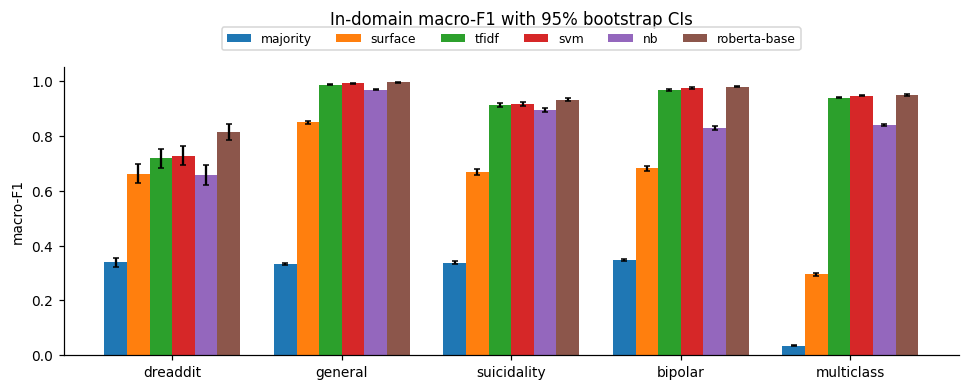

table saved: results/tables/table_screening_metrics.csv


**Table 3.** Screening metrics for the binary tasks at the default threshold. *Sensitivity* = share of positive posts detected; *PPV* = share of alarms that are correct.

sensitivity  specificity    ppv
task        model                                        
dreaddit    surface             0.729        0.598  0.656
            tfidf               0.762        0.673  0.711
            svm                 0.792        0.665  0.713
            nb                  0.964        0.397  0.627
            roberta-base        0.870        0.761  0.793
general     surface             0.851        0.846  0.848
            tfidf               0.987        0.985  0.985
            svm                 0.993        0.991  0.991
            nb                  0.986        0.949  0.951
            roberta-base        0.995        0.994  0.994
suicidality surface             0.703        0.636  0.651
            tfidf               0.912        0.913  0.910
            svm                 0.919        0.913  0.911
            nb                  0.908        0.881  0.881
            roberta-base        0.958        0.908  0.909
bipolar     surface             0.773        0.603  0.630
            tfidf               0.966        0.971  0.967
            svm                 0.971        0.977  0.974
            nb                  0.986        0.692  0.737
            roberta-base        0.979        0.980  0.978

In [25]:
fig, ax = plt.subplots(figsize=(1.7 * len(TASKS_TO_RUN) + 2, 3.4))
width = 0.8 / max(len(MODEL_ORDER), 1)
colors = plt.cm.tab10(np.arange(len(MODEL_ORDER)))
for j, model in enumerate(MODEL_ORDER):
    d = IN_DOMAIN[IN_DOMAIN["model"] == model].set_index("task").reindex(TASKS_TO_RUN)
    x = np.arange(len(TASKS_TO_RUN)) + (j - (len(MODEL_ORDER) - 1) / 2) * width
    err = np.vstack([d["macro_f1"] - d["ci_low"], d["ci_high"] - d["macro_f1"]])
    ax.bar(x, d["macro_f1"], width, yerr=err, capsize=2, label=model, color=colors[j])
ax.set_xticks(range(len(TASKS_TO_RUN)), TASKS_TO_RUN)
ax.set_ylabel("macro-F1"); ax.set_ylim(0, 1.05)
ax.legend(ncol=len(MODEL_ORDER), fontsize=8, loc="upper center", bbox_to_anchor=(0.5, 1.16))
ax.set_title("In-domain macro-F1 with 95% bootstrap CIs", pad=28)
savefig(fig, "fig_06_in_domain_macro_f1"); plt.show()

binary = IN_DOMAIN[IN_DOMAIN["task"].map(lambda t: SPEC[t]["k"] == 2) & (IN_DOMAIN["model"] != "majority")]
if not binary.empty:
    screen = (binary.set_index(["task", "model"])[["sensitivity", "specificity", "ppv"]]
              .reindex(TASKS_TO_RUN, level=0).round(3))
    save_table(screen, "table_screening_metrics")
    display(Markdown("**Table 3.** Screening metrics for the binary tasks at the default threshold. "
                     "*Sensitivity* = share of positive posts detected; *PPV* = share of alarms that are correct."))
    display(screen)

### 7.2 How much is shortcut? (RQ2)

The **shortcut share** expresses the surface model's gain over the majority floor as a fraction of a full model's gain:

$$\text{shortcut share} = \frac{F1_{\text{surface}} - F1_{\text{majority}}}{F1_{\text{full}} - F1_{\text{majority}}}$$

A value near 0 means the full model draws on information that style alone cannot supply; a value near 1 means that features ignoring *what* a post says already achieve almost everything.

A high share is **not by itself evidence of a shortcut**, because the surface features are of two kinds. Seven describe *genre and format* (length, URLs, line breaks, capitalisation, punctuation) and carry no psychological meaning. One - the rate of first-person singular pronouns - is an established *psychological* marker [7]. A task solved by genre features is being solved by recognising the register of a community, which is a shortcut [6]; a task solved by first-person rate is being solved, at least partly, by a genuine correlate of distress. §7.2b separates the two.

table saved: results/tables/table_shortcut_share.csv


**Table 4.** Shortcut share per task.

,surface F1,share vs tfidf,share vs roberta-base
task,,,
dreaddit,0.662,0.854,0.679
general,0.849,0.789,0.779
suicidality,0.669,0.577,0.557
bipolar,0.682,0.538,0.529
multiclass,0.295,0.287,0.284


figure saved: figures/fig_07_shortcut_share.png


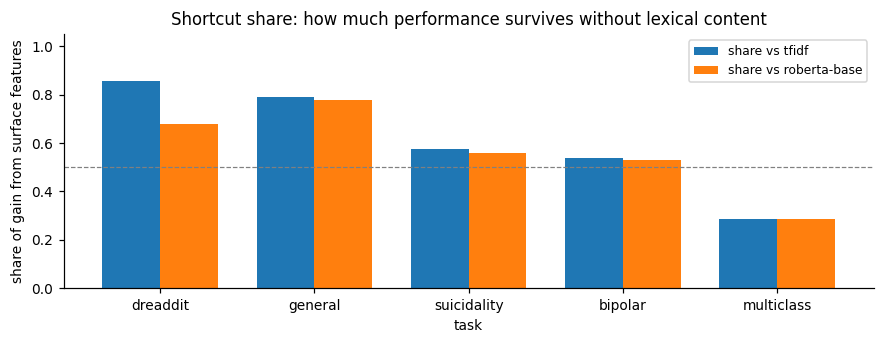

In [26]:
F = IN_DOMAIN.pivot(index="task", columns="model", values="macro_f1").reindex(TASKS_TO_RUN)
if {"majority", "surface"} <= set(F.columns):
    refs = [m for m in ["tfidf"] + TF_PRESENT if m in F.columns]
    SHORTCUT = pd.DataFrame({f"share vs {ref}": (F["surface"] - F["majority"]) / (F[ref] - F["majority"])
                             for ref in refs}).clip(lower=0)
    SHORTCUT.insert(0, "surface F1", F["surface"])
    save_table(SHORTCUT.round(3), "table_shortcut_share")
    display(Markdown("**Table 4.** Shortcut share per task."))
    display(SHORTCUT.round(3))

    fig, ax = plt.subplots(figsize=(1.5 * len(TASKS_TO_RUN) + 2, 3))
    share_cols = [c for c in SHORTCUT.columns if c.startswith("share")]
    SHORTCUT[share_cols].plot.bar(ax=ax, rot=0, width=0.75)
    ax.axhline(0.5, ls="--", lw=0.8, color="grey")
    ax.set_ylim(0, 1.05); ax.set_ylabel("share of gain from surface features")
    ax.set_title("Shortcut share: how much performance survives without lexical content")
    ax.legend(fontsize=8)
    savefig(fig, "fig_07_shortcut_share"); plt.show()

### 7.2b Decomposing the surface signal: genre or psychology?

The surface probe is re-trained on two disjoint subsets of its features: the first-person rate alone, and the seven genre-and-format features alone. Standardised coefficients of the full surface model show the direction and weight of each feature (positive = pushes towards the mental-health / stress class).

**How to read it.** If the genre features alone reproduce most of the surface score, the task is separable by the register of the communities involved - a shortcut. If the first-person rate alone carries most of it, the stylistic signal is psychologically meaningful. The two shares are **not additive**: correlated features can each recover much of the gain on their own (control posts, for example, both contain more links and use fewer first-person pronouns), so it is the comparison between the two columns that matters, not their sum.

table saved: results/tables/table_surface_decomposition.csv


**Table 4b.** Macro-F1 of the surface probe on feature subsets, and the share of the surface model's gain over the floor that each subset recovers on its own.

,majority,first-person only,genre & format only (7),all 8 surface,tfidf,genre share of surface gain,first-person share of surface gain
task,,,,,,,
dreaddit,0.339,0.645,0.598,0.662,0.718,0.801,0.945
general,0.334,0.831,0.756,0.849,0.986,0.819,0.965
suicidality,0.337,0.648,0.649,0.669,0.912,0.940,0.937
bipolar,0.348,0.651,0.631,0.682,0.969,0.846,0.907
multiclass,0.036,0.205,0.253,0.295,0.940,0.836,0.654


table saved: results/tables/table_surface_coefficients.csv
figure saved: figures/fig_07b_surface_coefficients.png


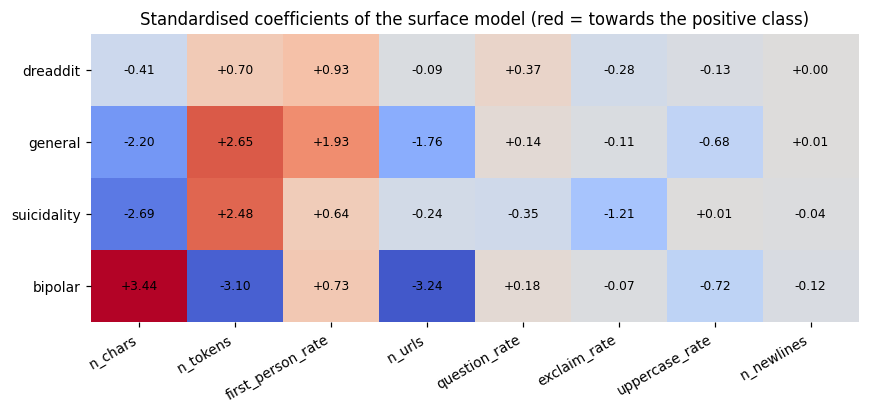

In [27]:
FP = ["first_person_rate"]
GENRE = [f for f in SURFACE_NAMES if f not in FP]
GROUPS = {"first-person only": FP, "genre & format only (7)": GENRE, "all 8 surface": SURFACE_NAMES}

rows, coefs = [], {}
for task in TASKS_TO_RUN:
    k = SPEC[task]["k"]
    tr, te = DATA[task]["train"], DATA[task]["test"]
    Xtr = pd.DataFrame(surface_features(tr["text"]), columns=SURFACE_NAMES)
    Xte = pd.DataFrame(surface_features(te["text"]), columns=SURFACE_NAMES)
    row = {"task": task}
    for gname, feats in GROUPS.items():
        sc = StandardScaler().fit(Xtr[feats])
        clf = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
        clf.fit(sc.transform(Xtr[feats]), tr["label"].to_numpy())
        probs = np.zeros((len(te), k))
        probs[:, clf.classes_] = clf.predict_proba(sc.transform(Xte[feats]))
        row[gname] = evaluate(te["label"].to_numpy(), probs, k)["macro_f1"]
        if feats is SURFACE_NAMES and k == 2:
            coefs[task] = pd.Series(clf.coef_[0], index=feats)
    rows.append(row)

DECOMP = pd.DataFrame(rows).set_index("task")
DECOMP.insert(0, "majority", F["majority"].reindex(DECOMP.index))
DECOMP["tfidf"] = F["tfidf"].reindex(DECOMP.index)
gain = (DECOMP["all 8 surface"] - DECOMP["majority"]).clip(lower=1e-9)
DECOMP["genre share of surface gain"] = ((DECOMP["genre & format only (7)"] - DECOMP["majority"]) / gain).clip(0, 1)
DECOMP["first-person share of surface gain"] = ((DECOMP["first-person only"] - DECOMP["majority"]) / gain).clip(0, 1)
save_table(DECOMP.round(3), "table_surface_decomposition")
display(Markdown("**Table 4b.** Macro-F1 of the surface probe on feature subsets, and the share of the "
                 "surface model's gain over the floor that each subset recovers on its own."))
display(DECOMP.round(3))

if coefs:
    C = pd.DataFrame(coefs).T[SURFACE_NAMES]
    save_table(C.round(3), "table_surface_coefficients")
    m = np.abs(C.values).max()
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(C) + 1.4))
    ax.imshow(C.values, cmap="coolwarm", vmin=-m, vmax=m, aspect="auto")
    for i in range(C.shape[0]):
        for j in range(C.shape[1]):
            ax.text(j, i, f"{C.values[i, j]:+.2f}", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(C.shape[1]), C.columns, rotation=30, ha="right")
    ax.set_yticks(range(C.shape[0]), C.index)
    for sp_ in ax.spines.values():
        sp_.set_visible(False)
    ax.set_title("Standardised coefficients of the surface model (red = towards the positive class)")
    savefig(fig, "fig_07b_surface_coefficients"); plt.show()

### 7.3 Statistical comparison of models

Paired bootstrap tests on the in-domain test sets, with Holm–Bonferroni correction across all comparisons. Each row asks whether the first model is genuinely better than the second, or whether the observed difference could plausibly arise from the particular test examples drawn.

In [28]:
pairs = [("tfidf", "surface"), ("svm", "tfidf"), ("tfidf", "nb")] + [(m, "tfidf") for m in TF_PRESENT]
rows = []
for task in TASKS_TO_RUN:
    for a, b in pairs:
        ra, rb = run_of(a, task), run_of(b, task)
        if not (ra and rb):
            continue
        y, pa = load_preds(ra["run_id"], f"{task}/test")
        _, pb = load_preds(rb["run_id"], f"{task}/test")
        d, lo, hi, p = paired_bootstrap(y, pa.argmax(1), pb.argmax(1), ra["k"])
        rows.append({"task": task, "comparison": f"{a} vs {b}", "delta macro-F1": d,
                     "ci_low": lo, "ci_high": hi, "p_raw": max(p, 1 / N_BOOTSTRAP)})
SIGNIF = pd.DataFrame(rows)
if not SIGNIF.empty:
    # Holm-Bonferroni: controls the family-wise error rate across all comparisons in the table
    p_raw = SIGNIF["p_raw"].to_numpy(); m = len(p_raw); order = np.argsort(p_raw)
    holm, running = np.empty(m), 0.0
    for rank, idx in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p_raw[idx])); holm[idx] = running
    fmt = lambda p: "< 0.001" if p <= 1 / N_BOOTSTRAP else f"{p:.3f}"
    SIGNIF["p"] = [fmt(p) for p in p_raw]
    SIGNIF["p (Holm)"] = [fmt(p) for p in holm]
    SIGNIF["significant (Holm, 5%)"] = holm < 0.05
    SIGNIF = SIGNIF.drop(columns="p_raw")
    save_table(SIGNIF.round(4), "table_significance", index=False)
    display(Markdown("**Table 5.** Paired bootstrap comparisons (one-sided test that the first model is better), "
                     "with Holm-Bonferroni correction across all comparisons. The 95% interval is two-sided, "
                     "so a one-sided p just below 0.05 can coexist with an interval that touches zero."))
    display(SIGNIF.round(4))

table saved: results/tables/table_significance.csv


**Table 5.** Paired bootstrap comparisons (one-sided test that the first model is better), with Holm-Bonferroni correction across all comparisons. The 95% interval is two-sided, so a one-sided p just below 0.05 can coexist with an interval that touches zero.

,task,comparison,delta macro-F1,ci_low,ci_high,p,p (Holm),"significant (Holm, 5%)"
0,dreaddit,tfidf vs surface,0.0552,0.0163,0.0921,0.005,0.020,True
1,dreaddit,svm vs tfidf,0.0106,-0.0092,0.0305,0.150,0.150,False
2,dreaddit,tfidf vs nb,0.0613,0.0270,0.0979,< 0.001,0.020,True
3,dreaddit,roberta-base vs tfidf,0.0981,0.0634,0.1336,< 0.001,0.020,True
4,general,tfidf vs surface,0.1375,0.1331,0.1421,< 0.001,0.020,True
5,general,svm vs tfidf,0.0054,0.0044,0.0064,< 0.001,0.020,True
6,general,tfidf vs nb,0.0188,0.0168,0.0206,< 0.001,0.020,True
7,general,roberta-base vs tfidf,0.0084,0.0070,0.0099,< 0.001,0.020,True
8,suicidality,tfidf vs surface,0.2435,0.2324,0.2552,< 0.001,0.020,True
9,suicidality,svm vs tfidf,0.0036,-0.0004,0.0076,0.035,0.070,False


### 7.4 Training variance across seeds

The dissertation's experiments used a single seed (42), so variability between fine-tuning runs was not measured; this is reported as a limitation (§11). Adding seeds to `TRANSFORMER_SEEDS` fills this section automatically.

In [29]:
seed_runs = [r for r in RUNS.values() if r["family"] == "transformer" and is_current(r)]
if len({r["seed"] for r in seed_runs}) > 1:
    sv = pd.DataFrame([{"model": r["model"], "task": r["task"], "seed": r["seed"],
                        "macro_f1": r["metrics"][f"{r['task']}/test"]["macro_f1"]} for r in seed_runs])
    SEEDS = sv.groupby(["task", "model"])["macro_f1"].agg(["mean", "std", "count"]).round(4)
    save_table(SEEDS, "table_seed_variance")
    display(SEEDS)
else:
    print("Only one seed so far. Add seeds to TRANSFORMER_SEEDS to measure training variance.")

Only one seed so far. Add seeds to TRANSFORMER_SEEDS to measure training variance.


### 7.5 Overfitting check

A model **overfits** when it fits its training data much better than data it has not seen, because it has memorised particular examples instead of learning patterns that generalise. The test sets already guard against this, since they are never used for training or for any decision. This section adds three direct checks:

1. **Training versus test performance (classical models).** Each classical model is refitted once on its full training set and scored on that same training data. The *gap* between training and test macro-F1 is the direct measure of overfitting.
2. **Cross-validation (Dreaddit).** On the smallest task, where overfitting is most likely, 5-fold cross-validation on the training set shows how much performance varies between subsets of the data. A test score inside the cross-validation range shows that the test result is not a lucky draw.
3. **Training, validation and test performance (transformer).** RoBERTa is fine-tuned again with the same settings and seed, and its selected checkpoint is scored on its own training data, on the validation set and on the test set. The training curves of §6.2 complement this: overfitting would appear there as validation performance falling while the training loss keeps decreasing.

Three figures summarise the checks:

- **Training versus test macro-F1** for every model and task: the length of each line is the gap.
- **Learning curves** of the classical models on Dreaddit: training and cross-validated macro-F1 as the training set grows from 10% to 100%. A wide gap that narrows as data are added is the classic sign of overfitting caused by too little data; two curves that have met mean that more data would not help.
- **Epoch curves** of RoBERTa on Dreaddit: training and validation macro-F1 after every epoch. Overfitting appears as the training curve continuing to rise while the validation curve flattens or falls.

**How to read it.** A high training score is not a problem in itself; a large gap is. A gap of a few points is normal for any model that learns from its data. A gap of tens of points, with a test score far below the training score, means that the model has memorised part of its training set. Validation and test scores that agree show that the selected checkpoint was not tuned to a lucky validation set.

**What this check cannot show.** It detects memorisation of *individual training examples*. It cannot detect shortcut learning, because a shortcut that exists in the training data also exists in the test data drawn from the same source, so it helps on both equally. That is examined by the generalisation experiments of §8.

The classical refit takes about as long as §5 (restrict `OVERFIT_CLASSICAL_TASKS` to save time); the learning curves take about a minute; the transformer check needs a GPU and takes two to three minutes for Dreaddit on a T4.

 surface | dreaddit     train 0.679 | test 0.662 | 0s
   tfidf | dreaddit     train 0.942 | test 0.718 | 1s
     svm | dreaddit     train 1.000 | test 0.728 | 1s
      nb | dreaddit     train 0.910 | test 0.656 | 1s
 surface | general      train 0.852 | test 0.849 | 27s
   tfidf | general      train 0.990 | test 0.986 | 97s
     svm | general      train 0.999 | test 0.992 | 97s
      nb | general      train 0.969 | test 0.968 | 88s
 surface | suicidality  train 0.672 | test 0.669 | 8s
   tfidf | suicidality  train 0.943 | test 0.912 | 27s
     svm | suicidality  train 0.986 | test 0.916 | 28s
      nb | suicidality  train 0.914 | test 0.895 | 25s
 surface | bipolar      train 0.687 | test 0.682 | 10s
   tfidf | bipolar      train 0.984 | test 0.969 | 37s
     svm | bipolar      train 0.999 | test 0.974 | 35s
      nb | bipolar      train 0.840 | test 0.828 | 34s
 surface | multiclass   train 0.299 | test 0.295 | 30s
   tfidf | multiclass   train 0.969 | test 0.940 | 122s
     svm | mul

roberta-base | dreaddit: train 0.913 | validation 0.861 | test 0.821 (cached run: 0.816)
table saved: results/tables/table_overfitting.csv


**Table 10.** Macro-F1 on the training data and on the held-out test data. The gap is the direct measure of overfitting; validation is shown for the transformer.

train  validation   test  gap (train - test)
task        model                                                     
dreaddit    surface       0.679         NaN  0.662               0.017
            tfidf         0.942         NaN  0.718               0.224
            svm           1.000         NaN  0.728               0.271
            nb            0.910         NaN  0.656               0.253
general     surface       0.852         NaN  0.849               0.003
            tfidf         0.990         NaN  0.986               0.003
            svm           0.999         NaN  0.992               0.008
            nb            0.969         NaN  0.968               0.001
suicidality surface       0.672         NaN  0.669               0.003
            tfidf         0.943         NaN  0.912               0.031
            svm           0.986         NaN  0.916               0.070
            nb            0.914         NaN  0.895               0.019
bipolar     surface       0.687         NaN  0.682               0.006
            tfidf         0.984         NaN  0.969               0.015
            svm           0.999         NaN  0.974               0.024
            nb            0.840         NaN  0.828               0.012
multiclass  surface       0.299         NaN  0.295               0.004
            tfidf         0.969         NaN  0.940               0.029
            svm           0.995         NaN  0.947               0.048
            nb            0.871         NaN  0.840               0.031
dreaddit    roberta-base  0.913       0.861  0.821               0.092

figure saved: figures/fig_06b_overfitting_gap.png


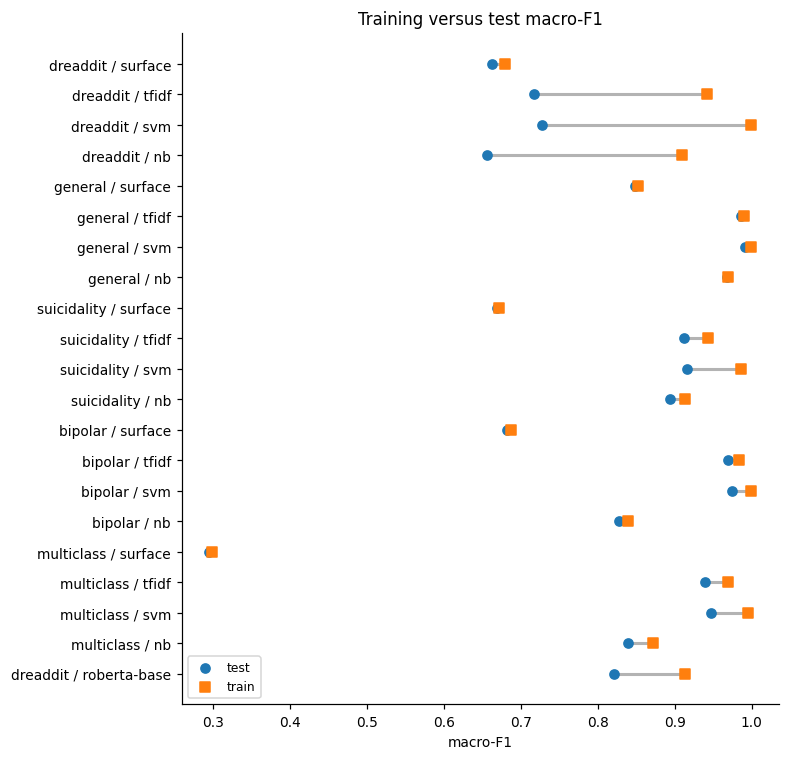

table saved: results/tables/table_cross_validation.csv


**Table 10b.** Five-fold cross-validation on the training data, compared with the test score.

CV mean  CV sd  CV min  CV max   test
task     model                                       
dreaddit tfidf    0.770  0.018   0.756   0.797  0.718
         svm      0.767  0.016   0.752   0.793  0.728
         nb       0.677  0.035   0.637   0.719  0.656

table saved: results/tables/table_learning_curves.csv
figure saved: figures/fig_06c_learning_curves_dreaddit.png


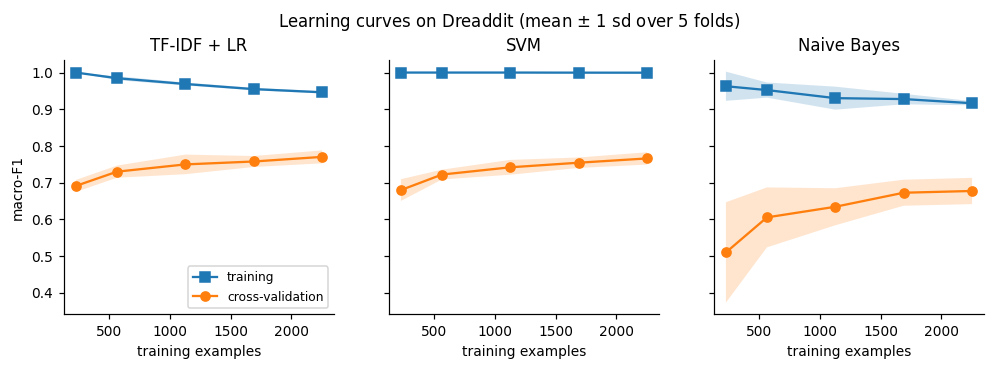

figure saved: figures/fig_06d_epoch_curves_dreaddit.png


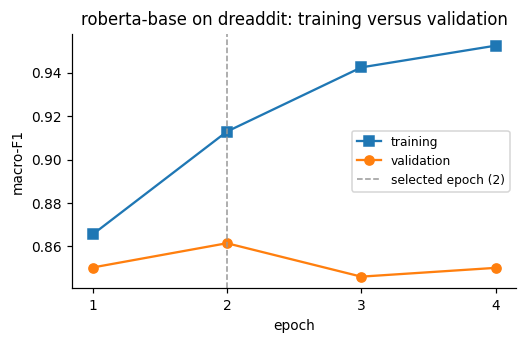

,epoch,train_loss,train_macro_f1,val_macro_f1
0,1,0.5481,0.8655,0.8503
1,2,0.3451,0.9129,0.8615
2,3,0.2446,0.9424,0.8461
3,4,0.1754,0.9524,0.8502


In [30]:
OVERFIT_CLASSICAL         = True          # refit each classical model once and score it on its training data
OVERFIT_CLASSICAL_TASKS   = TASKS_TO_RUN  # e.g. ["dreaddit", "suicidality"] to save time
OVERFIT_CV_TASKS          = ["dreaddit"]  # 5-fold cross-validation and learning curves (fast on small tasks)
OVERFIT_TRANSFORMER_TASKS = ["dreaddit"]  # re-fine-tune RoBERTa and score it on train / validation / test

from sklearn.model_selection import StratifiedKFold, train_test_split, learning_curve
from sklearn.metrics import make_scorer, f1_score
EPOCH_CURVES = {}

OF_ROWS = []

# ---- 1. classical models: training versus test macro-F1
if OVERFIT_CLASSICAL:
    for task in [t for t in OVERFIT_CLASSICAL_TASKS if t in TASKS_TO_RUN]:
        tr, k = DATA[task]["train"], SPEC[task]["k"]
        X, y = tr["text"].tolist(), tr["label"].to_numpy()
        for name in ["surface", "tfidf", "svm", "nb"]:
            r = run_of(name, task)
            if r is None:
                continue
            t0 = time.time()
            model = make_classical(name).fit(X, y)
            train_f1 = evaluate(y, aligned_proba(model, X, k), k)["macro_f1"]
            OF_ROWS.append({"task": task, "model": name, "train": train_f1, "validation": np.nan,
                            "test": r["metrics"][f"{task}/test"]["macro_f1"]})
            print(f"{name:>8} | {task:<12} train {train_f1:.3f} | test {OF_ROWS[-1]['test']:.3f}"
                  f" | {time.time() - t0:.0f}s")

# ---- 3. transformer: training, validation and test macro-F1 of the selected checkpoint
if OVERFIT_TRANSFORMER_TASKS and RUN_TRANSFORMERS and torch.cuda.is_available():
    model_name, seed = TRANSFORMER_MODELS[0], TRANSFORMER_SEEDS[0]
    tag = model_name.split("/")[-1]
    for task in OVERFIT_TRANSFORMER_TASKS:
        k = SPEC[task]["k"]
        model, tok, collate, info = fine_tune(task, model_name, seed=seed, max_train=TRANSFORMER_MAX_TRAIN,
                                              verbose=False, track_train=True)
        EPOCH_CURVES[task] = (pd.DataFrame(info["history"]), info["best_epoch"])
        # rebuild exactly the training subset that fine_tune used (same split, same seed)
        data = DATA[task]["train"]
        if TRANSFORMER_MAX_TRAIN and TRANSFORMER_MAX_TRAIN < len(data):
            data, _ = train_test_split(data, train_size=TRANSFORMER_MAX_TRAIN,
                                       stratify=data["label"], random_state=seed)
        tr, _ = train_test_split(data, test_size=VAL_FRAC, stratify=data["label"], random_state=seed)
        te = get_eval(f"{task}/test")
        tr_ds, _ = encode(tok, tr["text"], tr["label"])
        te_ds, _ = encode(tok, te["text"], te["label"])
        train_f1 = evaluate(tr_ds.labels, predict_probs(model, tr_ds, collate), k)["macro_f1"]
        test_f1 = evaluate(te_ds.labels, predict_probs(model, te_ds, collate), k)["macro_f1"]
        OF_ROWS.append({"task": task, "model": tag, "train": train_f1,
                        "validation": info["best_val_macro_f1"], "test": test_f1})
        cached = run_of(tag, task)
        print(f"{tag} | {task}: train {train_f1:.3f} | validation {info['best_val_macro_f1']:.3f} | "
              f"test {test_f1:.3f} (cached run: {cached['metrics'][f'{task}/test']['macro_f1']:.3f})"
              if cached else f"{tag} | {task}: train {train_f1:.3f} | test {test_f1:.3f}")
        del model; gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
elif OVERFIT_TRANSFORMER_TASKS:
    print("Transformer check skipped: it needs a GPU (Runtime -> Change runtime type -> T4 GPU). "
          "On a CPU, fine-tuning would take over an hour.")

if OF_ROWS:
    OVERFIT = pd.DataFrame(OF_ROWS)
    OVERFIT["gap (train - test)"] = OVERFIT["train"] - OVERFIT["test"]
    save_table(OVERFIT.round(3), "table_overfitting", index=False)
    display(Markdown("**Table 10.** Macro-F1 on the training data and on the held-out test data. "
                     "The gap is the direct measure of overfitting; validation is shown for the transformer."))
    display(OVERFIT.set_index(["task", "model"]).round(3))

    fig, ax = plt.subplots(figsize=(7, 0.32 * len(OVERFIT) + 1.2))
    labels = [f"{r.task} / {r.model}" for r in OVERFIT.itertuples()]
    ypos = np.arange(len(OVERFIT))
    ax.hlines(ypos, OVERFIT["test"], OVERFIT["train"], color="0.7", lw=2)
    ax.scatter(OVERFIT["test"], ypos, label="test", zorder=3)
    ax.scatter(OVERFIT["train"], ypos, label="train", marker="s", zorder=3)
    ax.set_yticks(ypos, labels); ax.invert_yaxis()
    ax.set_xlabel("macro-F1"); ax.set_title("Training versus test macro-F1")
    ax.legend(fontsize=8, loc="lower left")
    savefig(fig, "fig_06b_overfitting_gap"); plt.show()

# ---- 2. cross-validation on the training data of small tasks
CV_ROWS = []
for task in [t for t in OVERFIT_CV_TASKS if t in TASKS_TO_RUN]:
    tr, k = DATA[task]["train"], SPEC[task]["k"]
    X, y = np.asarray(tr["text"].tolist(), dtype=object), tr["label"].to_numpy()
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    for name in ["tfidf", "svm", "nb"]:
        r = run_of(name, task)
        scores = []
        for fit_idx, val_idx in folds.split(X, y):
            m = make_classical(name).fit(X[fit_idx].tolist(), y[fit_idx])
            scores.append(evaluate(y[val_idx], aligned_proba(m, X[val_idx].tolist(), k), k)["macro_f1"])
        CV_ROWS.append({"task": task, "model": name, "CV mean": np.mean(scores),
                        "CV sd": np.std(scores, ddof=1), "CV min": min(scores), "CV max": max(scores),
                        "test": r["metrics"][f"{task}/test"]["macro_f1"] if r else np.nan})
if CV_ROWS:
    CV_TABLE = pd.DataFrame(CV_ROWS)
    save_table(CV_TABLE.round(3), "table_cross_validation", index=False)
    display(Markdown("**Table 10b.** Five-fold cross-validation on the training data, compared with the test score."))
    display(CV_TABLE.set_index(["task", "model"]).round(3))

# ---- learning curves: training and cross-validated macro-F1 as the training set grows
LC_ROWS = []
macro = make_scorer(f1_score, average="macro")
for task in [t for t in OVERFIT_CV_TASKS if t in TASKS_TO_RUN]:
    tr = DATA[task]["train"]
    X, y = np.asarray(tr["text"].tolist(), dtype=object), tr["label"].to_numpy()
    for name in ["tfidf", "svm", "nb"]:
        sizes, train_sc, val_sc = learning_curve(
            make_classical(name), X, y, train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0], scoring=macro,
            cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED), shuffle=True, random_state=SEED)
        for n, a, b in zip(sizes, train_sc, val_sc):
            LC_ROWS.append({"task": task, "model": name, "n_train": int(n),
                            "train_mean": a.mean(), "train_sd": a.std(ddof=1),
                            "val_mean": b.mean(), "val_sd": b.std(ddof=1)})
if LC_ROWS:
    LC = pd.DataFrame(LC_ROWS)
    save_table(LC.round(4), "table_learning_curves", index=False)
    for task in LC["task"].unique():
        d = LC[LC["task"] == task]
        models = list(d["model"].unique())
        fig, axes = plt.subplots(1, len(models), figsize=(3.6 * len(models), 3.0), sharey=True)
        for ax, name in zip(np.atleast_1d(axes), models):
            m = d[d["model"] == name]
            for col, lab, mk in [("train", "training", "s"), ("val", "cross-validation", "o")]:
                ax.plot(m["n_train"], m[f"{col}_mean"], marker=mk, label=lab)
                ax.fill_between(m["n_train"], m[f"{col}_mean"] - m[f"{col}_sd"],
                                m[f"{col}_mean"] + m[f"{col}_sd"], alpha=0.2)
            ax.set_title({"tfidf": "TF-IDF + LR", "svm": "SVM", "nb": "Naive Bayes"}.get(name, name))
            ax.set_xlabel("training examples")
        np.atleast_1d(axes)[0].set_ylabel("macro-F1"); np.atleast_1d(axes)[0].legend(fontsize=8, loc="lower right")
        fig.suptitle(f"Learning curves on {task.capitalize()} (mean $\\pm$ 1 sd over 5 folds)", y=1.03)
        savefig(fig, f"fig_06c_learning_curves_{task}"); plt.show()

# ---- epoch curves of the transformer: training versus validation macro-F1 after every epoch
for task, (h, best) in EPOCH_CURVES.items():
    fig, ax = plt.subplots(figsize=(5.2, 3.0))
    ax.plot(h["epoch"], h["train_macro_f1"], marker="s", label="training")
    ax.plot(h["epoch"], h["val_macro_f1"], marker="o", label="validation")
    ax.axvline(best, color="0.6", ls="--", lw=1, label=f"selected epoch ({best})")
    ax.set_xticks(h["epoch"]); ax.set_xlabel("epoch"); ax.set_ylabel("macro-F1")
    ax.set_title(f"{TRANSFORMER_MODELS[0].split('/')[-1]} on {task}: training versus validation")
    ax.legend(fontsize=8)
    savefig(fig, f"fig_06d_epoch_curves_{task}"); plt.show()
    display(h[["epoch", "train_loss", "train_macro_f1", "val_macro_f1"]].round(4))


## 8. Generalisation (RQ3)

Three evaluation regimes of increasing difficulty are compared, following the protocol motivated by Harrigian et al. [5], who showed that mental-health classifiers trained on one social-media dataset often degrade sharply on another:

| Regime | Evaluation set | What changes |
|---|---|---|
| **In-domain** | same task, published test split | nothing — the usual benchmark setting |
| **External communities** | `general/external` | the subreddits; the labelling procedure is the same |
| **Cross-corpus** | the other member of the transfer group | the labelling procedure itself: subreddit membership ↔ human annotation |

The **oracle-threshold F1** re-tunes the decision threshold on the target data. It is *not* a valid test score - it uses target labels - but a diagnostic: when it recovers most of the lost F1, the model still ranks target posts well and the failure lies in calibration; when it does not, the failure lies in how the model ranks target posts, which no choice of threshold can repair.

table saved: results/tables/transfer_results.csv
figure saved: figures/fig_08_transfer_matrix.png


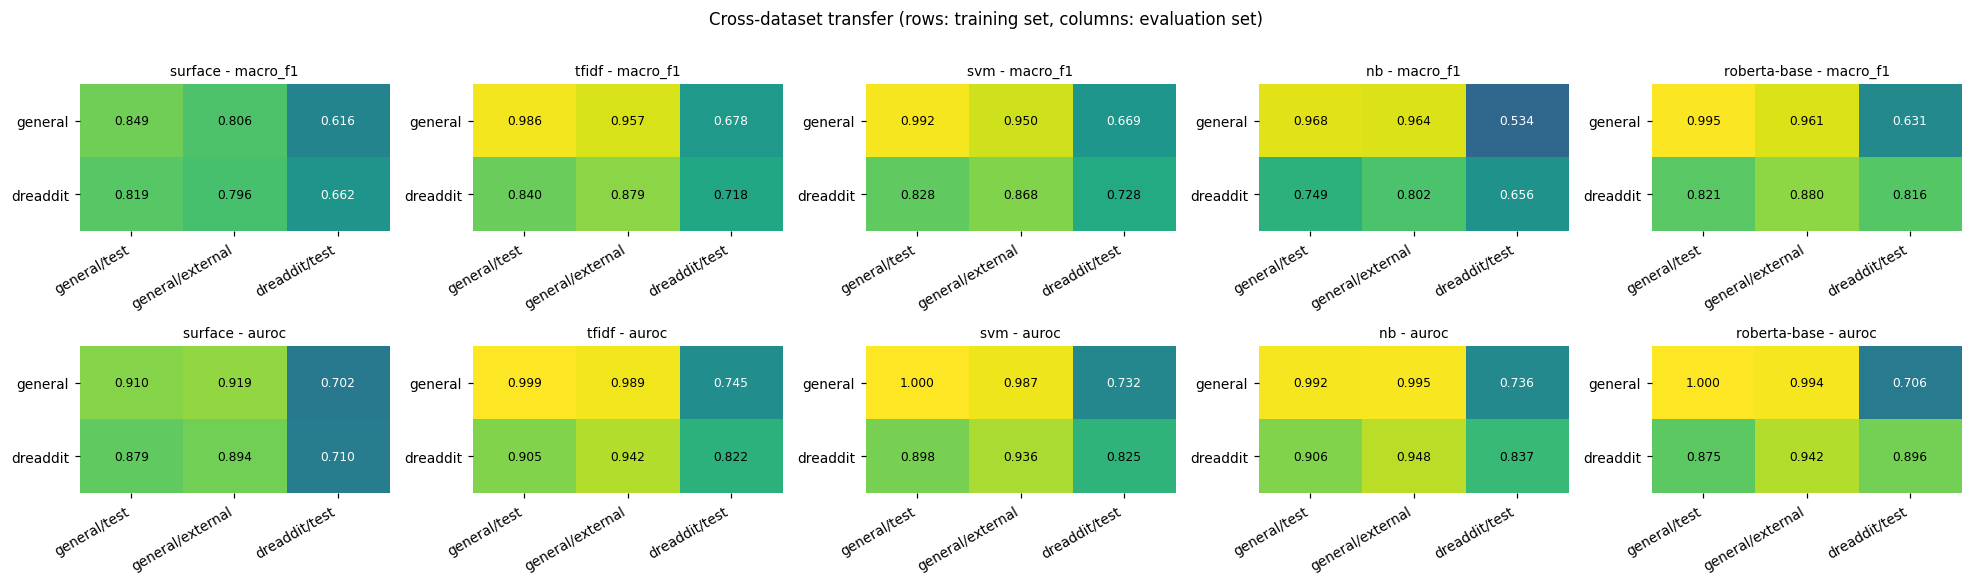

**Table 6.** Generalisation by regime. Compare macro-F1 with oracle-threshold F1 to separate calibration failure from ranking failure.

regime  macro_f1  auroc  oracle_f1  sensitivity  specificity
model        train    eval                                                                                        
surface      general  general/test                 in-domain     0.849  0.910      0.849        0.851        0.846
                      general/external  external communities     0.806  0.919      0.857        0.918        0.698
                      dreaddit/test             cross-corpus     0.616  0.702      0.665        0.886        0.388
             dreaddit general/test              cross-corpus     0.819  0.879      0.820        0.806        0.831
                      general/external          cross-corpus     0.796  0.894      0.832        0.892        0.703
                      dreaddit/test                in-domain     0.662  0.710      0.668        0.729        0.598
tfidf        general  general/test                 in-domain     0.986  0.999      0.986        0.987        0.985
                      general/external  external communities     0.957  0.989      0.957        0.949        0.964
                      dreaddit/test             cross-corpus     0.678  0.745      0.693        0.834        0.534
             dreaddit general/test              cross-corpus     0.840  0.905      0.841        0.804        0.877
                      general/external          cross-corpus     0.879  0.942      0.882        0.870        0.887
                      dreaddit/test                in-domain     0.718  0.822      0.734        0.762        0.673
svm          general  general/test                 in-domain     0.992  1.000      0.991        0.993        0.991
                      general/external  external communities     0.950  0.987      0.953        0.926        0.973
                      dreaddit/test             cross-corpus     0.669  0.732      0.678        0.767        0.574
             dreaddit general/test              cross-corpus     0.828  0.898      0.830        0.806        0.850
                      general/external          cross-corpus     0.868  0.936      0.874        0.874        0.861
                      dreaddit/test                in-domain     0.728  0.825      0.736        0.792        0.665
nb           general  general/test                 in-domain     0.968  0.992      0.968        0.986        0.949
                      general/external  external communities     0.964  0.995      0.976        0.988        0.940
                      dreaddit/test             cross-corpus     0.534  0.736      0.675        0.961        0.224
             dreaddit general/test              cross-corpus     0.749  0.906      0.842        0.925        0.587
                      general/external          cross-corpus     0.802  0.948      0.892        0.948        0.663
                      dreaddit/test                in-domain     0.656  0.837      0.751        0.964        0.397
roberta-base general  general/test                 in-domain     0.995  1.000      0.994        0.995        0.994
                      general/external  external communities     0.961  0.994      0.970        0.948        0.973
                      dreaddit/test             cross-corpus     0.631  0.706      0.664        0.831        0.452
             dreaddit general/test              cross-corpus     0.821  0.875      0.823        0.740        0.906
                      general/external          cross-corpus     0.880  0.942      0.884        0.820        0.942
                      dreaddit/test                in-domain     0.816  0.896      0.822        0.870        0.761

In [31]:
def oracle_f1(y, p1):
    ths = np.unique(np.quantile(p1, np.linspace(0.01, 0.99, 99)))
    return max(macro_f1_cm(confusion(y, (p1 >= t).astype(int), 2)) for t in ths)

if TRANSFER_ON:
    transfer_models = [m for m in MODEL_ORDER if m != "majority"]
    rows = []
    for model in transfer_models:
        for train in TRANSFER_GROUP:
            r = run_of(model, train)
            if not r:
                continue
            for e in TRANSFER_EVAL:
                if e not in r["metrics"]:
                    continue
                y, probs = load_preds(r["run_id"], e)
                m = r["metrics"][e]
                regime = ("in-domain" if e == f"{train}/test" else
                          "external communities" if e == "general/external" and train == "general"
                          else "cross-corpus")
                rows.append({"model": model, "train": train, "eval": e, "regime": regime,
                             "macro_f1": m["macro_f1"], "auroc": m["auroc"],
                             "oracle_f1": oracle_f1(y, probs[:, 1]),
                             "sensitivity": m["recall"][1], "specificity": m["recall"][0]})
    TRANSFER = pd.DataFrame(rows)
    save_table(TRANSFER.round(4), "transfer_results", index=False)

    fig, axes = plt.subplots(2, len(transfer_models), figsize=(3.6 * len(transfer_models), 5.2), squeeze=False)
    for j, model in enumerate(transfer_models):
        sub = TRANSFER[TRANSFER["model"] == model]
        for i, metric in enumerate(["macro_f1", "auroc"]):
            mat = sub.pivot(index="train", columns="eval", values=metric).reindex(
                index=TRANSFER_GROUP, columns=TRANSFER_EVAL)
            heatmap(axes[i, j], mat, f"{model} - {metric}", vmin=0.3 if metric == "macro_f1" else 0.5)
    fig.suptitle("Cross-dataset transfer (rows: training set, columns: evaluation set)", y=1.01)
    fig.tight_layout(); savefig(fig, "fig_08_transfer_matrix"); plt.show()

    display(Markdown("**Table 6.** Generalisation by regime. Compare macro-F1 with oracle-threshold F1 "
                     "to separate calibration failure from ranking failure."))
    display(TRANSFER.set_index(["model", "train", "eval"]).round(3))
else:
    print("Cross-dataset study disabled (needs both 'general' and 'dreaddit').")

### 8.1 Score distributions under distribution shift

Histograms of the predicted probability of distress, separated by true label. In-domain, the two classes should form well-separated peaks around 0 and 1. Under shift, watch for the peaks sliding towards each other (the model loses the signal) or sliding *together* to one side of 0.5 (the model still separates the classes, but the threshold no longer sits between them).

figure saved: figures/fig_09_score_distributions.png


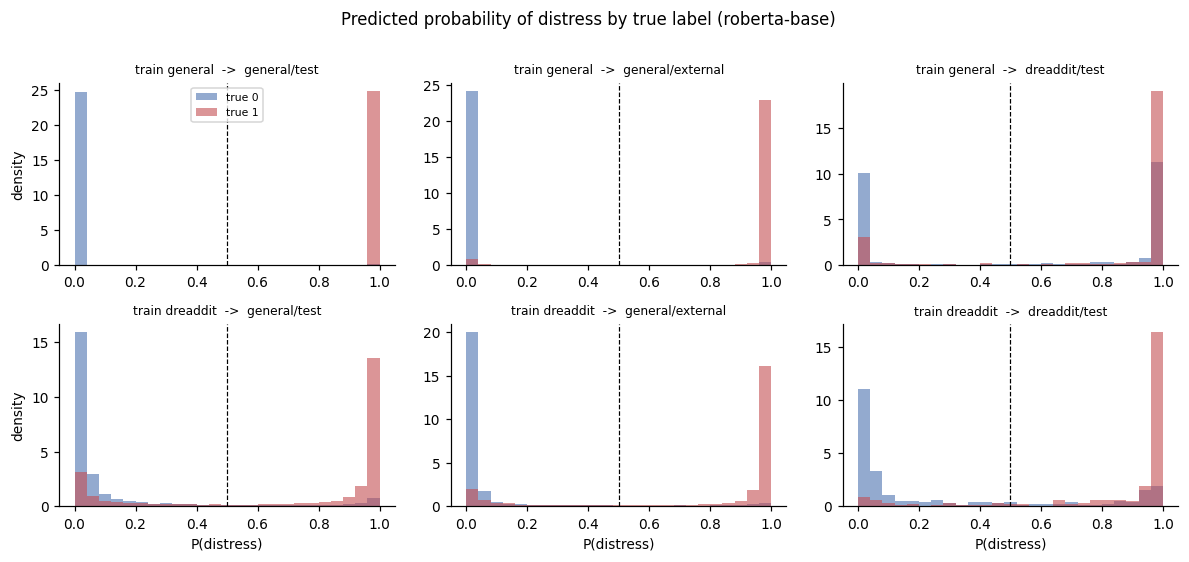

figure saved: figures/fig_10_roc_transfer.png


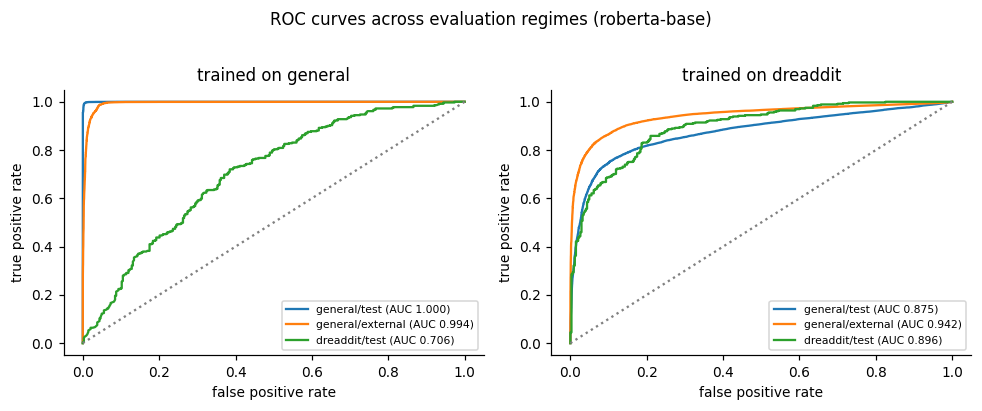

In [32]:
if TRANSFER_ON:
    fig, axes = plt.subplots(len(TRANSFER_GROUP), len(TRANSFER_EVAL), figsize=(11, 5), squeeze=False)
    for i, train in enumerate(TRANSFER_GROUP):
        r = run_of(FOCUS, train)
        for j, e in enumerate(TRANSFER_EVAL):
            ax = axes[i, j]
            if not r or e not in r["metrics"]:
                ax.axis("off"); continue
            y, probs = load_preds(r["run_id"], e)
            bins = np.linspace(0, 1, 26)
            ax.hist(probs[y == 0, 1], bins=bins, alpha=0.6, density=True, label="true 0", color="#4C72B0")
            ax.hist(probs[y == 1, 1], bins=bins, alpha=0.6, density=True, label="true 1", color="#C44E52")
            ax.axvline(0.5, ls="--", color="black", lw=0.8)
            ax.set_title(f"train {train}  ->  {e}", fontsize=8)
            if j == 0: ax.set_ylabel("density")
            if i == len(TRANSFER_GROUP) - 1: ax.set_xlabel("P(distress)")
    axes[0, 0].legend(fontsize=7, loc="upper center")
    fig.suptitle(f"Predicted probability of distress by true label ({FOCUS})", y=1.01)
    fig.tight_layout(); savefig(fig, "fig_09_score_distributions"); plt.show()

    fig, axes = plt.subplots(1, len(TRANSFER_GROUP), figsize=(9, 3.6), squeeze=False)
    for i, train in enumerate(TRANSFER_GROUP):
        r, ax = run_of(FOCUS, train), axes[0, i]
        if not r:
            ax.axis("off"); continue
        for e in TRANSFER_EVAL:
            if e in r["metrics"]:
                y, probs = load_preds(r["run_id"], e)
                fpr, tpr, _ = roc_curve(y, probs[:, 1])
                ax.plot(fpr, tpr, label=f"{e} (AUC {r['metrics'][e]['auroc']:.3f})")
        ax.plot([0, 1], [0, 1], ls=":", color="grey")
        ax.set(title=f"trained on {train}", xlabel="false positive rate", ylabel="true positive rate")
        ax.legend(fontsize=7, loc="lower right")
    fig.suptitle(f"ROC curves across evaluation regimes ({FOCUS})", y=1.02)
    fig.tight_layout(); savefig(fig, "fig_10_roc_transfer"); plt.show()

### 8.2 Performance by community

This analysis would report the accuracy of the *general* model on each subreddit of its evaluation sets. The released Hasan & Saquer files, however, do not record the subreddit of each post, so it cannot be run and is skipped. Dreaddit does record the community of every excerpt, and §8.2b performs the corresponding analysis there.

In [33]:
ext = DATA.get("general", {}).get("external")
if ext is not None and ext["subreddit"].astype(str).str.len().gt(0).any() and run_of(FOCUS, "general"):
    r, rows = run_of(FOCUS, "general"), []
    for e in ["general/test", "general/external"]:
        y, probs = load_preds(r["run_id"], e)
        df = get_eval(e).assign(pred=probs.argmax(1), p1=probs[:, 1])
        for sub, g in df.groupby("subreddit"):
            rows.append({"set": e.split("/")[1], "subreddit": sub, "n": len(g), "label": int(g["label"].iloc[0]),
                         "accuracy": (g["label"] == g["pred"]).mean(), "mean P(distress)": g["p1"].mean()})
    BY_SUB = pd.DataFrame(rows).sort_values(["set", "accuracy"])
    save_table(BY_SUB.round(4), "table_by_subreddit", index=False)

    fig, ax = plt.subplots(figsize=(8, 0.28 * len(BY_SUB) + 1))
    lab = BY_SUB["set"] + " | r/" + BY_SUB["subreddit"]
    ax.barh(lab, BY_SUB["accuracy"], color=np.where(BY_SUB["label"] == 1, "#C44E52", "#4C72B0"))
    ax.set_xlim(0, 1); ax.set_xlabel("accuracy"); ax.invert_yaxis()
    ax.set_title(f"Accuracy per community, {FOCUS} trained on general (red = labelled positive)")
    savefig(fig, "fig_11_accuracy_by_subreddit"); plt.show()
    display(BY_SUB.round(3).set_index(["set", "subreddit"]))
else:
    print("No subreddit information available for the general task -- analysis skipped.")

No subreddit information available for the general task -- analysis skipped.


### 8.2b Where does the general model fail on Dreaddit?

Dreaddit records the community each excerpt came from, which makes it possible to see *where* a model trained on the general task goes wrong. Two readings of its false positives compete. If they are spread evenly across communities, the model has simply learned a different notion of distress. If they concentrate in communities devoted to mental health (such as r/anxiety or r/ptsd), the model is responding to the *community register* of a post rather than to the stress it expresses - and, under the general task's own labelling rule, many of those excerpts would count as positive. In that case the transfer "failure" is, at least in part, a disagreement between two operationalisations of distress. Counts per community are small, so differences of a few points should not be over-read.

table saved: results/tables/table_dreaddit_by_community.csv


**Table 6b.** Models trained on *general*, evaluated on Dreaddit, by source community (sorted by false-positive rate of roberta-base).

n  stressed %  n not stressed  false-positive rate  recall (stressed)  mean P(distress), not stressed
             subreddit                                                                                                                  
roberta-base r/food_pantry         6      50.000               3                1.000              1.000                           0.939
             r/ptsd              126      64.286              45                0.844              0.938                           0.845
             r/survivorsofabuse   66      42.424              38                0.842              0.929                           0.817
             r/anxiety           142      57.042              61                0.721              0.975                           0.704
             r/domesticviolence   72      65.278              25                0.560              0.809                           0.544
             r/stress             14      71.429               4                0.500              0.700                           0.556
             r/relationships     141      42.553              81                0.444              0.650                           0.434
             r/almosthomeless     19      63.158               7                0.286              0.750                           0.292
             r/homeless           52      34.615              34                0.235              0.556                           0.248
             r/assistance         66      31.818              45                0.200              0.619                           0.199

figure saved: figures/fig_10c_dreaddit_false_positives_by_community.png


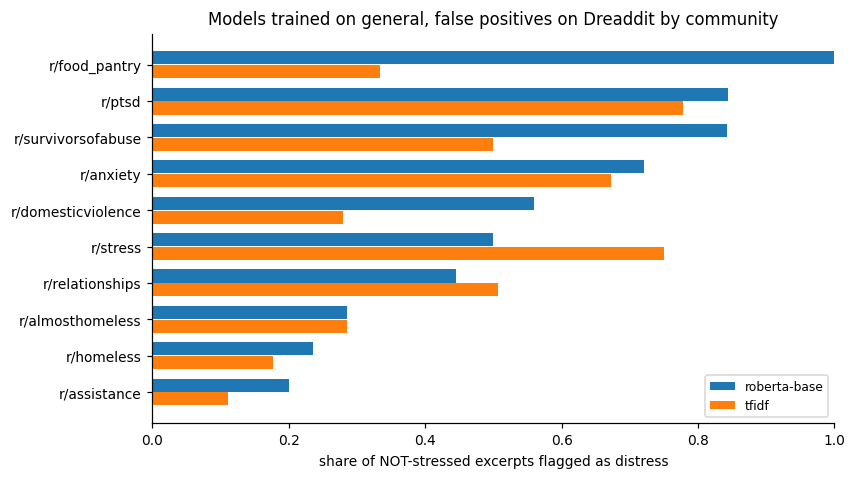

In [34]:
dd_test = DATA.get("dreaddit", {}).get("test")
if TRANSFER_ON and dd_test is not None and dd_test["subreddit"].astype(str).str.len().gt(0).any():
    rows = []
    for model in dict.fromkeys([FOCUS, "tfidf"]):
        r = run_of(model, "general")
        if not r or "dreaddit/test" not in r["metrics"]:
            continue
        y, probs = load_preds(r["run_id"], "dreaddit/test")
        df = dd_test.assign(p1=probs[:, 1], pred=probs.argmax(1))
        for sub, g in df.groupby("subreddit"):
            neg, pos = g[g["label"] == 0], g[g["label"] == 1]
            rows.append({"model": model, "subreddit": f"r/{sub}", "n": len(g),
                         "stressed %": 100 * g["label"].mean(),
                         "n not stressed": len(neg),
                         "false-positive rate": (neg["pred"] == 1).mean() if len(neg) else np.nan,
                         "recall (stressed)": (pos["pred"] == 1).mean() if len(pos) else np.nan,
                         "mean P(distress), not stressed": neg["p1"].mean() if len(neg) else np.nan})
    BY_DD = pd.DataFrame(rows)
    save_table(BY_DD.round(3), "table_dreaddit_by_community", index=False)
    display(Markdown(f"**Table 6b.** Models trained on *general*, evaluated on Dreaddit, by source community "
                     f"(sorted by false-positive rate of {FOCUS})."))
    focus = BY_DD[BY_DD["model"] == FOCUS].sort_values("false-positive rate", ascending=False)
    display(BY_DD.set_index(["model", "subreddit"]).loc[[FOCUS]].reindex(
        pd.MultiIndex.from_product([[FOCUS], focus["subreddit"]])).round(3))

    fig, ax = plt.subplots(figsize=(8, 0.34 * len(focus) + 1.2))
    for j, model in enumerate(BY_DD["model"].unique()):
        d = BY_DD[BY_DD["model"] == model].set_index("subreddit").reindex(focus["subreddit"])
        ax.barh(np.arange(len(d)) + (j - 0.5) * 0.38, d["false-positive rate"], height=0.36, label=model)
    ax.set_yticks(range(len(focus)), focus["subreddit"]); ax.invert_yaxis()
    ax.set_xlim(0, 1); ax.set_xlabel("share of NOT-stressed excerpts flagged as distress")
    ax.set_title("Models trained on general, false positives on Dreaddit by community")
    ax.legend(fontsize=8, loc="lower right")
    savefig(fig, "fig_10c_dreaddit_false_positives_by_community"); plt.show()
else:
    print("No community information for Dreaddit -- analysis skipped.")

### 8.3 How many labelled examples repair a transferred model?

When a model transfers with high AUROC but low macro-F1, it still *ranks* target posts correctly; only its decision threshold is wrong. That suggests the cheapest adaptation there is: keep the model unchanged, label a small number of target posts, and re-choose the threshold on them.

For every transfer pair, *n* target posts (*n* = 10 … 500) are drawn at random, the threshold that maximises macro-F1 on them is selected, and the model is evaluated with that threshold on **all remaining** target posts - so the reported score is never computed on the posts used to choose the threshold. Each *n* is repeated 100 times; the band shows the 2.5–97.5 percentile range across draws.

This complements recent work on cross-platform shift in mental-health NLP [14], which found that temperature scaling repairs calibration without restoring discrimination and that target labels were more useful as training data. Here the axis of shift is different - the platform stays the same and only the **labelling procedure** changes - and the question is narrower and practical: *how many* target labels are needed, when the ranking survives, to recover the lost decision performance without retraining?

**A caution the results make visible.** Re-tuning is not free. When the fixed threshold is already close to the oracle, choosing a new threshold from a handful of examples adds estimation noise and can *lower* performance slightly. In Table 9, a missing value in the last column therefore means either that there was no meaningful gap to recover, or that it was not recovered with up to 500 labels - the first two columns tell which. In practice, recalibration should follow a check that a gap exists, not replace it.

table saved: results/tables/table_threshold_recalibration.csv
table saved: results/tables/table_threshold_recalibration_summary.csv


**Table 9.** Macro-F1 after re-choosing only the decision threshold on *n* labelled target posts (evaluated on the remaining posts). *Labels for 90% of gap*: smallest *n* that recovers 90% of the difference between the fixed 0.5 threshold and the oracle threshold.

fixed 0.5  oracle  with 50 labels  labels for 90% of gap
model        transfer                                                                              
nb           dreaddit -> general/external      0.802   0.892           0.881                  100.0
             dreaddit -> general/test          0.749   0.842           0.827                  100.0
             general -> dreaddit/test          0.534   0.675           0.651                    NaN
             general -> general/external       0.964   0.976           0.964                  500.0
roberta-base dreaddit -> general/external      0.880   0.884           0.871                    NaN
             dreaddit -> general/test          0.821   0.823           0.812                    NaN
             general -> dreaddit/test          0.631   0.664           0.633                    NaN
             general -> general/external       0.961   0.970           0.955                  500.0
surface      dreaddit -> general/external      0.796   0.832           0.818                  500.0
             dreaddit -> general/test          0.819   0.820           0.804                    NaN
             general -> dreaddit/test          0.616   0.665           0.634                    NaN
             general -> general/external       0.806   0.857           0.842                  500.0
svm          dreaddit -> general/external      0.868   0.874           0.856                    NaN
             dreaddit -> general/test          0.828   0.830           0.812                    NaN
             general -> dreaddit/test          0.669   0.678           0.651                    NaN
             general -> general/external       0.950   0.953           0.937                    NaN
tfidf        dreaddit -> general/external      0.879   0.882           0.868                    NaN
             dreaddit -> general/test          0.840   0.841           0.829                    NaN
             general -> dreaddit/test          0.678   0.693           0.663                    NaN
             general -> general/external       0.957   0.957           0.945                    NaN

figure saved: figures/fig_10b_threshold_recalibration.png


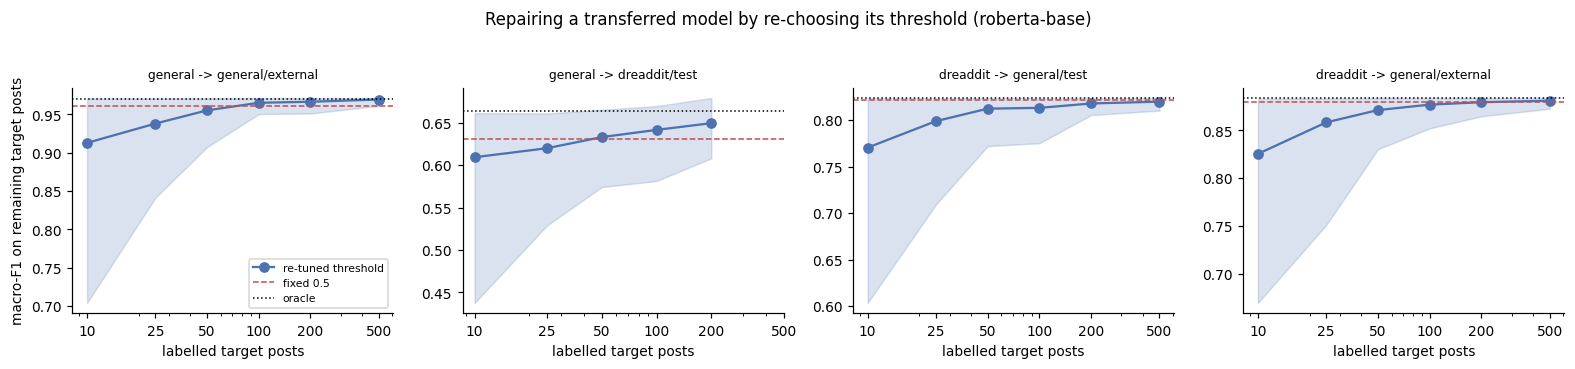

In [35]:
RECAL_N = [10, 25, 50, 100, 200, 500]
RECAL_REPEATS = 100

def f1_at(y, p1, t):
    return macro_f1_cm(confusion(y, (p1 >= t).astype(int), 2))

def best_threshold(y, p1):
    cands = np.unique(p1)
    scores = [f1_at(y, p1, t) for t in cands]
    return cands[int(np.argmax(scores))]

if TRANSFER_ON:
    pairs = [(tr, e) for tr in TRANSFER_GROUP for e in TRANSFER_EVAL if e != f"{tr}/test"]
    rng = np.random.default_rng(SEED)
    rows = []
    for model in [m for m in MODEL_ORDER if m != "majority"]:
        for train, e in pairs:
            r = run_of(model, train)
            if not r or e not in r["metrics"]:
                continue
            y, probs = load_preds(r["run_id"], e)
            p1, N = probs[:, 1], len(y)
            fixed, oracle = f1_at(y, p1, 0.5), oracle_f1(y, p1)
            for n in RECAL_N:
                if n >= N // 2:
                    continue
                vals = []
                for _ in range(RECAL_REPEATS):
                    idx = rng.permutation(N)
                    cal, rest = idx[:n], idx[n:]
                    if len(np.unique(y[cal])) < 2:
                        continue
                    t = best_threshold(y[cal], p1[cal])
                    vals.append(f1_at(y[rest], p1[rest], t))
                vals = np.array(vals)
                rows.append({"model": model, "transfer": f"{train} -> {e}", "n_labelled": n,
                             "macro_f1_mean": vals.mean(), "p2.5": np.quantile(vals, 0.025),
                             "p97.5": np.quantile(vals, 0.975), "fixed_0.5": fixed, "oracle": oracle,
                             "gap_recovered": (vals.mean() - fixed) / (oracle - fixed) if oracle > fixed + 1e-9 else np.nan})
    RECAL = pd.DataFrame(rows)
    save_table(RECAL.round(4), "table_threshold_recalibration", index=False)

    # smallest n that recovers >= 90% of the gap between the fixed threshold and the oracle
    def n90(g):
        ok = g[g["gap_recovered"] >= 0.9]
        return int(ok["n_labelled"].min()) if len(ok) else np.nan
    SUMMARY = (RECAL.groupby(["model", "transfer"])
               .apply(lambda g: pd.Series({"fixed 0.5": g["fixed_0.5"].iloc[0], "oracle": g["oracle"].iloc[0],
                                           "with 50 labels": g.loc[g["n_labelled"] == 50, "macro_f1_mean"].mean(),
                                           "labels for 90% of gap": n90(g)}), include_groups=False)
               .round(3))
    save_table(SUMMARY, "table_threshold_recalibration_summary")
    display(Markdown("**Table 9.** Macro-F1 after re-choosing only the decision threshold on *n* labelled "
                     "target posts (evaluated on the remaining posts). *Labels for 90% of gap*: smallest *n* that "
                     "recovers 90% of the difference between the fixed 0.5 threshold and the oracle threshold."))
    display(SUMMARY)

    sub = RECAL[RECAL["model"] == FOCUS]
    if not sub.empty:
        transfers = sub["transfer"].unique()
        fig, axes = plt.subplots(1, len(transfers), figsize=(3.6 * len(transfers), 3.2), squeeze=False)
        for ax, tr_name in zip(axes[0], transfers):
            d = sub[sub["transfer"] == tr_name]
            ax.plot(d["n_labelled"], d["macro_f1_mean"], marker="o", color="#4C72B0", label="re-tuned threshold")
            ax.fill_between(d["n_labelled"], d["p2.5"], d["p97.5"], alpha=0.2, color="#4C72B0")
            ax.axhline(d["fixed_0.5"].iloc[0], ls="--", color="#C44E52", lw=1, label="fixed 0.5")
            ax.axhline(d["oracle"].iloc[0], ls=":", color="black", lw=1, label="oracle")
            ax.set_xscale("log"); ax.set_xticks(RECAL_N, [str(n) for n in RECAL_N])
            ax.set_title(tr_name, fontsize=8); ax.set_xlabel("labelled target posts")
        axes[0, 0].set_ylabel("macro-F1 on remaining target posts")
        axes[0, 0].legend(fontsize=7, loc="lower right")
        fig.suptitle(f"Repairing a transferred model by re-choosing its threshold ({FOCUS})", y=1.03)
        fig.tight_layout(); savefig(fig, "fig_10b_threshold_recalibration"); plt.show()
else:
    print("Cross-dataset study disabled.")

## 9. Error analysis (RQ4)

### 9.1 Confusions between conditions

Row-normalised confusion matrices for the multi-class task. Off-diagonal mass shows which conditions the models cannot tell apart. Clinically related conditions - for example depression and bipolar disorder, whose depressive phases share much of their vocabulary - are expected to be the hardest pairs.

figure saved: figures/fig_12_multiclass_confusion.png


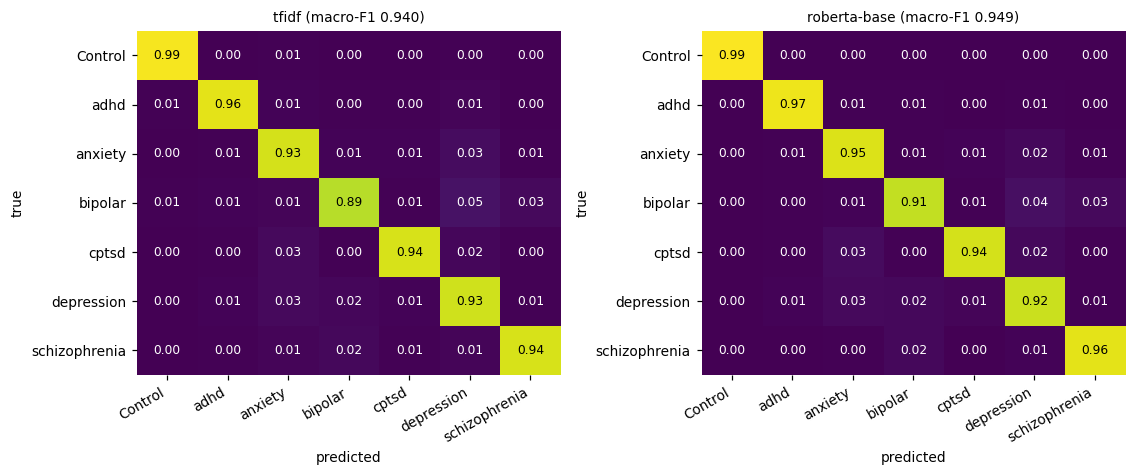

table saved: results/tables/table_multiclass_per_class_f1.csv


**Table 7.** Per-class F1, multi-class task.

model,roberta-base,tfidf
class,,
Control,0.993,0.982
adhd,0.973,0.963
anxiety,0.937,0.922
bipolar,0.923,0.914
cptsd,0.950,0.949
depression,0.909,0.901
schizophrenia,0.957,0.947


**Table 8.** Most frequent confusions (share of the true class).

rate
model        true          predicted           
tfidf        bipolar       depression     0.048
roberta-base bipolar       depression     0.041
tfidf        anxiety       depression     0.033
roberta-base cptsd         anxiety        0.027
             depression    anxiety        0.027
             bipolar       schizophrenia  0.027
tfidf        cptsd         anxiety        0.027
             depression    anxiety        0.025
             bipolar       schizophrenia  0.025
             schizophrenia bipolar        0.023
roberta-base depression    bipolar        0.022
             cptsd         depression     0.022

In [36]:
if "multiclass" in TASKS_TO_RUN:
    models = [m for m in ["tfidf"] + TF_PRESENT if run_of(m, "multiclass")]
    names = pretty_names("multiclass")
    if models:
        fig, axes = plt.subplots(1, len(models), figsize=(5.2 * len(models), 4.4), squeeze=False)
        pair_rows, class_rows = [], []
        for ax, model in zip(axes[0], models):
            r = run_of(model, "multiclass")
            cm = np.array(r["metrics"]["multiclass/test"]["confusion"], dtype=float)
            norm = cm / cm.sum(1, keepdims=True)
            heatmap(ax, pd.DataFrame(norm, index=names, columns=names),
                    f"{model} (macro-F1 {r['metrics']['multiclass/test']['macro_f1']:.3f})", fmt="{:.2f}")
            ax.set_xlabel("predicted"); ax.set_ylabel("true")
            for i in range(len(names)):
                for j in range(len(names)):
                    if i != j:
                        pair_rows.append({"model": model, "true": names[i], "predicted": names[j], "rate": norm[i, j]})
            m = r["metrics"]["multiclass/test"]
            for c, n in enumerate(names):
                p, rc = m["precision"][c], m["recall"][c]
                class_rows.append({"model": model, "class": n, "precision": p, "recall": rc,
                                   "f1": 2 * p * rc / (p + rc) if p + rc else 0.0})
        fig.tight_layout(); savefig(fig, "fig_12_multiclass_confusion"); plt.show()
        PER_CLASS = pd.DataFrame(class_rows).pivot(index="class", columns="model", values="f1").round(3)
        save_table(PER_CLASS, "table_multiclass_per_class_f1")
        display(Markdown("**Table 7.** Per-class F1, multi-class task.")); display(PER_CLASS)
        top = pd.DataFrame(pair_rows).sort_values("rate", ascending=False).groupby("model").head(6)
        display(Markdown("**Table 8.** Most frequent confusions (share of the true class)."))
        display(top.round(3).set_index(["model", "true", "predicted"]))
else:
    print("multiclass task not run.")

### 9.2 Most confident errors

The posts on which the model is most confidently wrong are shown for the *general* task. Reading them is the most direct way to see *why* a model fails: mislabelled data, sarcasm, a control post that discusses mental health, or a clinical post written in a neutral register.

> **Ethics note.** These are real posts written by real people, some in distress. They are displayed here for analysis only. In the dissertation, do **not** quote them verbatim - verbatim text can be searched and traced back to its author. Describe or paraphrase them instead, following the protocols of Benton et al. [11]. **Clear the output of the next cell before sharing or submitting this notebook.**

In [ ]:
task = "general" if "general" in TASKS_TO_RUN else TASKS_TO_RUN[0]
r = run_of(FOCUS, task)
if r and SPEC[task]["k"] == 2:
    y, probs = load_preds(r["run_id"], f"{task}/test")
    df = DATA[task]["test"].assign(p1=probs[:, 1], pred=probs.argmax(1))
    fp = df[(df["label"] == 0) & (df["pred"] == 1)].nlargest(5, "p1")
    fn = df[(df["label"] == 1) & (df["pred"] == 0)].nsmallest(5, "p1")
    for title, part in [("FALSE POSITIVES  (control posts flagged as distress)", fp),
                        ("FALSE NEGATIVES  (distress posts missed)", fn)]:
        print(f"\n{title}  -- model: {FOCUS}, task: {task}\n" + "-" * 100)
        for _, row in part.iterrows():
            sub = f"r/{row['subreddit']} " if str(row["subreddit"]) else ""
            print(f"P(distress)={row['p1']:.3f} {sub}| {row['text'][:280]!r}")
    print(f"\nerror counts: {len(df[(df.label == 0) & (df.pred == 1)])} false positives, "
          f"{len(df[(df.label == 1) & (df.pred == 0)])} false negatives of {len(df)}")

## 10. Summary and export

In [38]:
ALL = pd.DataFrame([{"run_id": rid, "family": r["family"], "model": r["model"], "train": r["task"],
                     "seed": r.get("seed"), "eval": e, "n": m["n"], "macro_f1": m["macro_f1"],
                     "auroc": m["auroc"], "accuracy": m["accuracy"]}
                    for rid, r in RUNS.items() for e, m in r["metrics"].items()])
save_table(ALL.round(4), "all_runs_long", index=False)

lines = ["### Headline findings (generated from the cached results)"]
for task in TASKS_TO_RUN:
    d = IN_DOMAIN[(IN_DOMAIN["task"] == task) & (IN_DOMAIN["model"] != "majority")]
    if not d.empty:
        b = d.loc[d["macro_f1"].idxmax()]
        lines.append(f"- **{task}**: best in-domain model **{b.model}**, macro-F1 {b.macro_f1:.3f} "
                     f"[{b.ci_low:.3f}, {b.ci_high:.3f}]" + (f", AUROC {b.auroc:.3f}" if pd.notna(b.auroc) else ""))
if "SHORTCUT" in globals() and "share vs tfidf" in SHORTCUT:
    s = SHORTCUT["share vs tfidf"].dropna()
    lines.append(f"- **Shortcut share** (surface vs TF-IDF) ranges from {s.min():.0%} ({s.idxmin()}) "
                 f"to {s.max():.0%} ({s.idxmax()}).")
if TRANSFER_ON and "TRANSFER" in globals() and not TRANSFER.empty:
    for train in TRANSFER_GROUP:
        t = TRANSFER[(TRANSFER["model"] == FOCUS) & (TRANSFER["train"] == train)].set_index("eval")
        if f"{train}/test" in t.index:
            base = t.loc[f"{train}/test", "macro_f1"]
            for e in t.index:
                if e != f"{train}/test":
                    lines.append(f"- **{FOCUS}** trained on *{train}* -> *{e}*: macro-F1 {t.loc[e, 'macro_f1']:.3f} "
                                 f"({t.loc[e, 'macro_f1'] - base:+.3f} vs in-domain), AUROC {t.loc[e, 'auroc']:.3f}, "
                                 f"oracle-threshold F1 {t.loc[e, 'oracle_f1']:.3f}")
display(Markdown("\n".join(lines)))

print("\nFigures:"); [print("  ", p.name) for p in sorted(FIG_DIR.glob("*.png"))]
print("Tables:");  [print("  ", p.name) for p in sorted(TABLE_DIR.glob("*.csv"))]

table saved: results/tables/all_runs_long.csv


### Headline findings (generated from the cached results)
- **dreaddit**: best in-domain model **roberta-base**, macro-F1 0.816 [0.787, 0.842], AUROC 0.896
- **general**: best in-domain model **roberta-base**, macro-F1 0.995 [0.994, 0.996], AUROC 1.000
- **suicidality**: best in-domain model **roberta-base**, macro-F1 0.932 [0.926, 0.938], AUROC 0.980
- **bipolar**: best in-domain model **roberta-base**, macro-F1 0.980 [0.977, 0.983], AUROC 0.998
- **multiclass**: best in-domain model **roberta-base**, macro-F1 0.949 [0.946, 0.952], AUROC 0.997
- **Shortcut share** (surface vs TF-IDF) ranges from 29% (multiclass) to 85% (dreaddit).
- **roberta-base** trained on *general* -> *general/external*: macro-F1 0.961 (-0.034 vs in-domain), AUROC 0.994, oracle-threshold F1 0.970
- **roberta-base** trained on *general* -> *dreaddit/test*: macro-F1 0.631 (-0.364 vs in-domain), AUROC 0.706, oracle-threshold F1 0.664
- **roberta-base** trained on *dreaddit* -> *general/test*: macro-F1 0.821 (+0.006 vs in-domain), AUROC 0.875, oracle-threshold F1 0.823
- **roberta-base** trained on *dreaddit* -> *general/external*: macro-F1 0.880 (+0.065 vs in-domain), AUROC 0.942, oracle-threshold F1 0.884


Figures:
   fig_01_cross_file_overlap.png
   fig_02_class_distribution.png
   fig_03_length_by_class.png
   fig_04_linguistic_markers.png
   fig_05_training_curves.png
   fig_06_in_domain_macro_f1.png
   fig_06b_overfitting_gap.png
   fig_06c_learning_curves_dreaddit.png
   fig_06d_epoch_curves_dreaddit.png
   fig_07_shortcut_share.png
   fig_07b_surface_coefficients.png
   fig_08_transfer_matrix.png
   fig_09_score_distributions.png
   fig_10_roc_transfer.png
   fig_10b_threshold_recalibration.png
   fig_10c_dreaddit_false_positives_by_community.png
   fig_12_multiclass_confusion.png
Tables:
   all_runs_long.csv
   cleaning_log.csv
   cross_file_overlap.csv
   cross_task_label_agreement.csv
   dataset_summary.csv
   in_domain_results.csv
   linguistic_markers.csv
   table_cross_validation.csv
   table_dreaddit_by_community.csv
   table_in_domain_auroc.csv
   table_in_domain_macro_f1.csv
   table_learning_curves.csv
   table_multiclass_per_class_f1.csv
   table_overfitting.csv
   tabl

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

### 10.1 Quantities derived for the text

A few numbers quoted in the dissertation are not printed by any table above, because they are simple derivations from them. They are computed here so that every number in the text can be traced to this notebook:

- the F1 score of the **stress class** on Dreaddit, the metric reported by the authors of Dreaddit [2] and therefore the comparable figure;
- the **positive predictive value** of the main model on *suicidality* at illustrative population prevalences of 5% and 1%, from its sensitivity and specificity by Bayes' rule;
- the **shortcut share** relative to every lexical model, not only those shown in Table 4;
- **Fisher's exact tests** comparing false-positive rates and recall between groups of Dreaddit communities (§8.2b). The grouping is by theme and was defined after inspecting the results, so these tests are exploratory.

In [39]:
from scipy.stats import fisher_exact

# stress-class F1 on Dreaddit
r = run_of(FOCUS, "dreaddit")
if r:
    m = r["metrics"]["dreaddit/test"]
    p, rc = m["precision"][1], m["recall"][1]
    print(f"{FOCUS}, Dreaddit: stress-class F1 = {2 * p * rc / (p + rc):.3f}")

# positive predictive value at illustrative prevalences
r = run_of(FOCUS, "suicidality")
if r:
    sens, spec = r["metrics"]["suicidality/test"]["recall"][1], r["metrics"]["suicidality/test"]["recall"][0]
    for prev in (0.50, 0.05, 0.01):
        ppv = sens * prev / (sens * prev + (1 - spec) * (1 - prev))
        ratio = f"{(1 - ppv) / ppv:.1f} false alarms per correct detection" if ppv > 0 else "no correct detections"
        print(f"{FOCUS}, suicidality: prevalence {prev:>4.0%} -> PPV {ppv:.1%}, {ratio}")

# shortcut share relative to every lexical model
F_ALL = IN_DOMAIN.pivot(index="task", columns="model", values="macro_f1").reindex(TASKS_TO_RUN)
SHARE_ALL = pd.DataFrame({m: (F_ALL["surface"] - F_ALL["majority"]) / (F_ALL[m] - F_ALL["majority"])
                          for m in ["tfidf", "svm", "nb"] + TF_PRESENT if m in F_ALL})
display(Markdown("**Shortcut share relative to every lexical model** (values above 1 mean that the surface "
                 "model outperformed the reference model)."))
display((100 * SHARE_ALL).round(1))

# Fisher's exact tests between groups of Dreaddit communities (exploratory)
GROUPS = {"mental health and trauma": ["r/ptsd", "r/survivorsofabuse", "r/anxiety"],
          "interpersonal": ["r/domesticviolence", "r/relationships"],
          "financial hardship": ["r/homeless", "r/almosthomeless", "r/assistance", "r/food_pantry"]}
if "BY_DD" in globals() and len(BY_DD):
    f = BY_DD[BY_DD["model"] == FOCUS].copy()
    f["n stressed"] = f["n"] - f["n not stressed"]
    f["fp"] = (f["false-positive rate"].fillna(0) * f["n not stressed"]).round().astype(int)
    f["tp"] = (f["recall (stressed)"].fillna(0) * f["n stressed"]).round().astype(int)
    rows = []
    for g, subs in GROUPS.items():
        s = f[f["subreddit"].isin(subs)]
        rows.append({"group": g, "false positives": int(s["fp"].sum()), "not stressed": int(s["n not stressed"].sum()),
                     "detected": int(s["tp"].sum()), "stressed": int(s["n stressed"].sum())})
    G = pd.DataFrame(rows).set_index("group")
    G["false-positive rate"] = G["false positives"] / G["not stressed"]
    G["recall"] = G["detected"] / G["stressed"]
    display(G.round(3))
    a, b = G.loc["mental health and trauma"], G.loc["financial hardship"]
    if min(a["not stressed"], b["not stressed"], a["stressed"], b["stressed"]) > 0:
        _, p_fp = fisher_exact([[a["false positives"], a["not stressed"] - a["false positives"]],
                                [b["false positives"], b["not stressed"] - b["false positives"]]])
        _, p_rec = fisher_exact([[a["detected"], a["stressed"] - a["detected"]],
                                 [b["detected"], b["stressed"] - b["detected"]]])
        print(f"Fisher's exact test, mental health and trauma vs financial hardship: "
              f"false-positive rate p = {p_fp:.1e}; recall p = {p_rec:.1e}")


roberta-base, Dreaddit: stress-class F1 = 0.830
roberta-base, suicidality: prevalence  50% -> PPV 91.2%, 0.1 false alarms per correct detection
roberta-base, suicidality: prevalence   5% -> PPV 35.3%, 1.8 false alarms per correct detection
roberta-base, suicidality: prevalence   1% -> PPV 9.5%, 9.5 false alarms per correct detection


**Shortcut share relative to every lexical model** (values above 1 mean that the surface model outperformed the reference model).

,tfidf,svm,nb,roberta-base
task,,,,
dreaddit,85.4,83.1,101.9,67.9
general,78.9,78.3,81.3,77.9
suicidality,57.7,57.3,59.5,55.7
bipolar,53.8,53.3,69.6,52.9
multiclass,28.7,28.5,32.3,28.4


,false positives,not stressed,detected,stressed,false-positive rate,recall
group,,,,,,
mental health and trauma,114,144,181,190,0.792,0.953
interpersonal,50,106,77,107,0.472,0.720
financial hardship,22,89,35,54,0.247,0.648


Fisher's exact test, mental health and trauma vs financial hardship: false-positive rate p = 2.0e-16; recall p = 3.2e-08


## 11. Limitations and threats to validity

- **Construct validity of the labels.** In the Hasan & Saquer suite a positive label means that a post was written in a mental-health community and passed self-identification filtering. Only 1–2% of posts were human-verified, and that verification measured agreement between annotators, not clinical diagnosis. The models therefore detect *community-associated language*, which is related to - but not the same as - the presence of a disorder.
- **Shortcut learning.** §7.2 quantifies how much performance is attainable from style alone. High in-domain scores must be read in that light [6].
- **Post-level, not user-level, and not temporal.** None of the datasets records posting histories. The models detect *indicators* in individual posts; early detection in the strict sense - flagging a user as early as possible in a chronological stream, scored with delay-aware metrics such as ERDE [12] - is beyond what these data support.
- **Prevalence.** Class distributions are curated and near-balanced. At realistic population prevalence, the positive predictive value of the same classifier would be far lower than Table 3 suggests.
- **Author leakage.** The published splits are at post level with no user identifiers, so different posts by the same author may appear in both training and test data and inflate in-domain scores. The external and cross-corpus evaluations are not affected by this.
- **Construct mismatch in transfer.** Dreaddit annotates acute stress rather than mental disorder, so the cross-corpus experiment measures transfer between related but distinct constructs.
- **Malformed source rows.** A small number of rows in the released CSV files are broken by unescaped line breaks (counts in §2). They are removed where detectable; fragments that carry a valid label cannot be detected and remain as noise.
- **Scope.** English-language Reddit only; results need not hold for other platforms, languages or periods.
- **Truncation and variance.** Posts beyond 256 sub-word tokens are truncated: 28–40% of training posts in the Hasan & Saquer tasks, against under 1% in Dreaddit (rates in §6). Near-ceiling in-domain scores suggest the opening of a post carries enough signal, but longer inputs or head-and-tail truncation [18] may matter under distribution shift, where the length difference between corpora is itself part of the shift. Bootstrap intervals capture test-sampling variance but not the variance between fine-tuning runs; additional seeds address the latter.

## 12. Ethics and reproducibility

**Ethics.** Data were used under the terms of their public releases. No attempt was made to identify, contact or profile any author; no user-level information beyond the released text and community name was used; no post is quoted verbatim in the dissertation [11]. The models are research artefacts for studying detection and generalisation and are not validated for clinical or monitoring use.

**Reproducibility.** Fixed random seeds for all stochastic steps; the published train/test splits; library versions recorded in `results/environment.json`; every experiment's configuration, metrics and per-example predictions cached in `results/cache/`. Re-running this notebook regenerates every table and figure.

## References

[1] K. Hasan and J. Saquer, "A benchmark suite of Reddit-derived datasets for mental health detection," in *Proc. CSCI*, 2025, arXiv:2604.23458. Dataset: doi:10.5281/zenodo.17114739.

[2] E. Turcan and K. McKeown, "Dreaddit: A Reddit dataset for stress analysis in social media," in *Proc. LOUHI Workshop at EMNLP*, 2019, pp. 97–107.

[3] Y. Liu *et al.*, "RoBERTa: A robustly optimized BERT pretraining approach," arXiv:1907.11692, 2019.

[4] S. Ji *et al.*, "MentalBERT: Publicly available pretrained language models for mental healthcare," in *Proc. LREC*, 2022.

[5] K. Harrigian, C. Aguirre, and M. Dredze, "Do models of mental health based on social media data generalize?," in *Findings of EMNLP*, 2020.

[6] R. Geirhos *et al.*, "Shortcut learning in deep neural networks," *Nature Machine Intelligence*, vol. 2, 2020.

[7] S. Rude, E.-M. Gortner, and J. Pennebaker, "Language use of depressed and depression-vulnerable college students," *Cognition and Emotion*, vol. 18, no. 8, 2004.

[8] M. Al-Mosaiwi and T. Johnstone, "In an absolute state: Elevated use of absolutist words is a marker specific to anxiety, depression, and suicidal ideation," *Clinical Psychological Science*, vol. 6, no. 4, 2018.

[9] T. Berg-Kirkpatrick, D. Burkett, and D. Klein, "An empirical investigation of statistical significance in NLP," in *Proc. EMNLP-CoNLL*, 2012.

[10] R. Dror, G. Baumer, S. Shlomov, and R. Reichart, "The hitchhiker's guide to testing statistical significance in natural language processing," in *Proc. ACL*, 2018.

[11] A. Benton, G. Coppersmith, and M. Dredze, "Ethical research protocols for social media health research," in *Proc. First ACL Workshop on Ethics in NLP*, 2017.

[12] D. E. Losada and F. Crestani, "A test collection for research on depression and language use," in *Proc. CLEF*, 2016.

[13] I. Loshchilov and F. Hutter, "Decoupled weight decay regularization," in *Proc. ICLR*, 2019.

[14] R. S. Pall and S. Yadav, "Cross-platform generalisation failure in mental health natural language processing: A five-axis fairness audit of transformer models on social media," arXiv:2608.26138, 2026.

[15] T. Joachims, "Text categorization with support vector machines: Learning with many relevant features," in *Proc. ECML*, 1998.

[16] A. McCallum and K. Nigam, "A comparison of event models for naive Bayes text classification," in *Proc. AAAI Workshop on Learning for Text Categorization*, 1998.

[17] J. Platt, "Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods," in *Advances in Large Margin Classifiers*, MIT Press, 1999.

[18] C. Sun, X. Qiu, Y. Xu, and X. Huang, "How to fine-tune BERT for text classification?," in *Proc. China National Conference on Chinese Computational Linguistics (CCL)*, 2019.

[19] S. Holm, "A simple sequentially rejective multiple test procedure," *Scandinavian Journal of Statistics*, vol. 6, no. 2, pp. 65–70, 1979.